# Longitudinal proficiency versus matchup: final integrated EDA

**Question:** When does individual champion proficiency outweigh the population matchup advantage of choosing another champion?

This notebook describes the immutable `20261020T180254240509Z` preparation snapshot. Global Master+ patch 16.19 is primary; NA Master+ is a paired sensitivity benchmark. It fits no models and selects no thresholds. All outcome exploration uses completed training games only. Full-sample analyses describe composition, pregame variables, candidate support, and benchmark agreement.

Sources read for interpretation: snapshot README, data dictionary and preparation metadata; `final_dataset_helpers.py` experience/candidate definitions; `longitudinal_pipeline.py` expanding-history definitions; existing `hlr_EDA.ipynb` feature semantics and saved chronological split outputs. No collection, preparation, API calls, or web access are required.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
%matplotlib inline

start = Path.cwd().resolve()
ROOT = next((p for p in [start, *start.parents]
             if (p / 'hlr_model/data/final/20261020T180254240509Z/README.md').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run from the repository root or hlr_model/.')
DATA = ROOT / 'hlr_model/data/final/20261020T180254240509Z'
readme = (DATA / 'README.md').read_text()
dictionary = pd.read_csv(DATA / 'data_dictionary.csv')
metadata = json.loads((DATA / 'preparation_metadata.json').read_text())
obs = pd.read_parquet(DATA / 'observed_global_analysis.parquet')
paired = pd.read_parquet(DATA / 'observed_paired_region_analysis.parquet')
candidates = pd.read_parquet(DATA / 'candidate_champion_comparisons.parquet')
KEY = ['puuid', 'match_id']
RATE = 'global_raw_matchup_winrate_pct'
N = 'global_matchup_games'
required = KEY + ['timestamp','end_timestamp','win','champion_id','lane','side',
    'is_main_champion','prior_total_games','prior_champion_games','prior_champion_wr',
    'prior_champion_wr_beta11','prior_champion_usage_share','prior_main_champion_usage_share', RATE,N]
assert set(required) <= set(obs)
assert not obs.duplicated(KEY).any() and not paired.duplicated(KEY).any()
assert not candidates.duplicated(KEY + ['candidate_champion_id']).any()
assert (len(obs), len(paired), len(candidates)) == (7227,7214,83523)
assert obs[RATE].notna().all() and obs.win.isin([0,1]).all()
print('Brief loading sanity check: dimensions, observed keys, and essential columns passed.')
display(pd.DataFrame({'dataset':['Primary observed','Paired observed','Candidate comparisons'],
                      'rows':[len(obs),len(paired),len(candidates)],
                      'columns':[obs.shape[1],paired.shape[1],candidates.shape[1]]}))
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
pd.set_option('display.max_columns',12)
pd.set_option('display.max_rows',20)
def show(df, digits=2):
    formats = {}
    probability_names = {'win_rate','observed_wr','wr','actual_pick_wr','raw_mean','beta11_mean',
        'raw_extreme_share','extreme_rate_share','mean_main_share'}
    for col in df.columns:
        if col in probability_names:
            formats[col] = '{:.1%}'
        elif pd.api.types.is_integer_dtype(df[col]):
            formats[col] = '{:,}'
    display(df.style.format(formats, precision=digits, na_rep='—'))
def note(s): display(Markdown(s))
def utc(ms): return pd.to_datetime(ms, unit='ms', utc=True)
def done(): plt.tight_layout(); plt.show(); plt.close('all')
EXP_LABELS = ['0','1–4','5–14','15–29','30+']
MATCH_LABELS = ['<45%','45–<50%','50–<55%','55%+']
def exp_bin(x): return pd.cut(x, [-1,0,4,14,29,np.inf], labels=EXP_LABELS)
def matchup_bin(x): return pd.cut(x, [-np.inf,45,50,55,np.inf], right=False, labels=MATCH_LABELS)
obs['pick'] = np.where(obs.is_main_champion,'All-role main','Off-main')
obs['experience_group'] = exp_bin(obs.prior_champion_games)
obs['matchup_group'] = matchup_bin(obs[RATE])

Brief loading sanity check: dimensions, observed keys, and essential columns passed.


,dataset,rows,columns
0,Primary observed,7227,269
1,Paired observed,7214,269
2,Candidate comparisons,83523,285


## 1. Data overview and variable guide — full primary sample

One observed row is a sampled **player in one target match**, not a distinct match or an independent player. Two focal players can share a match. Candidate rows are player-game–candidate records and do not add observed outcomes. These tables preserve hundreds of source and audit columns; they are not ready-made predictor matrices.

,Count
Player-games,7227
Players,184
Unique matches,6797
Selected champions,173
Player–champion combinations,1722
Matches with multiple focal players,408
Rows in shared matches,838
Most focal players in a match,3


Target kickoff range (UTC): 2026-09-23 12:20:17.734000+00:00 to 2026-10-07 08:33:21.723000+00:00


,Games per player
0.000000,1.00
0.100000,5.00
0.250000,14.00
0.500000,27.00
0.750000,58.00
0.900000,88.70
0.950000,106.70
1.000000,197.00


pick,All-role main,Off-main,All
lane,,,
adc,747,916,1663
jungle,483,804,1287
mid,845,896,1741
support,365,838,1203
top,547,786,1333
All,2987,4240,7227


,Matches
Sampled players per match,
1,6389
2,386
3,22


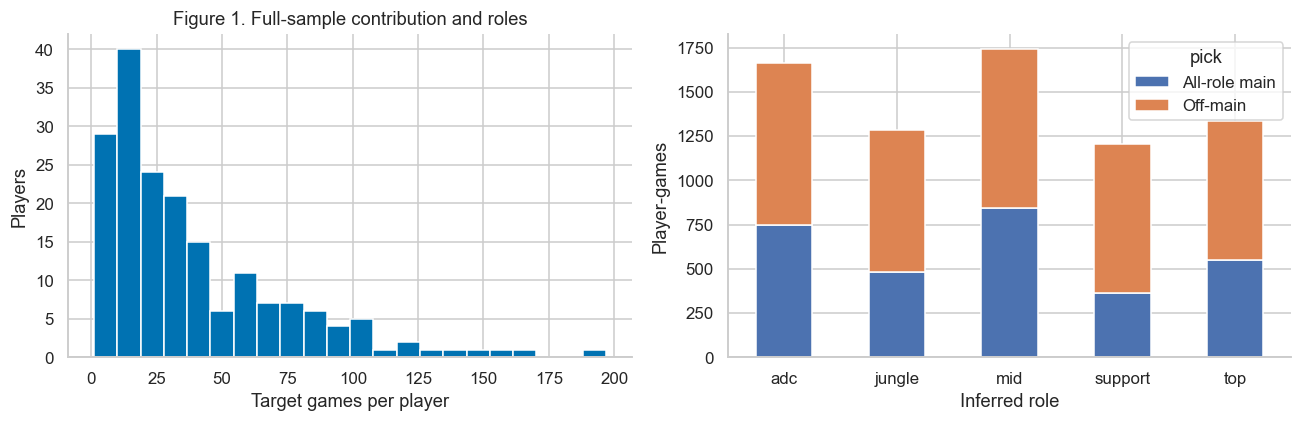

The sample has **7,227 rows from 184 players**, but only **6,797 distinct matches**. The median player contributes 27 games; the 90th percentile is 88.7. 408 matches contain multiple focal players (838 rows), so row independence is inappropriate.

In [2]:
games = obs.groupby('puuid').size()
shared = obs.groupby('match_id').size()
pc_full = obs.groupby(['puuid','champion_id']).size()
display(pd.Series({'Player-games':len(obs),'Players':obs.puuid.nunique(),
    'Unique matches':obs.match_id.nunique(),'Selected champions':obs.champion_id.nunique(),
    'Player–champion combinations':len(pc_full),
    'Matches with multiple focal players':int(shared.gt(1).sum()),
    'Rows in shared matches':int(shared[shared.gt(1)].sum()),
    'Most focal players in a match':shared.max()}, name='Count').to_frame())
print('Target kickoff range (UTC):', utc(obs.timestamp.min()), 'to', utc(obs.timestamp.max()))
show(games.quantile([0,.1,.25,.5,.75,.9,.95,1]).rename('Games per player').to_frame())
display(pd.crosstab(obs.lane,obs.pick,margins=True))
display(shared.value_counts().sort_index().rename_axis('Sampled players per match').rename('Matches').to_frame())
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].hist(games,bins=22,color='#0072B2',edgecolor='white')
axes[0].set(xlabel='Target games per player',ylabel='Players',title='Figure 1. Full-sample contribution and roles')
pd.crosstab(obs.lane,obs.pick).plot.bar(stacked=True,ax=axes[1],rot=0)
axes[1].set(xlabel='Inferred role',ylabel='Player-games'); done()
note(f'The sample has **{len(obs):,} rows from {len(games)} players**, but only **{len(shared):,} distinct matches**. '
     f'The median player contributes {games.median():.0f} games; the 90th percentile is {games.quantile(.9):.1f}. '
     f'{shared.gt(1).sum()} matches contain multiple focal players ({shared[shared.gt(1)].sum()} rows), so row independence is inappropriate.')

In [3]:
guide = pd.DataFrame([
 ('Outcome','win','Binary actual result; response only'),
 ('Pregame experience','prior_total_games; prior_champion_games; prior_champion_usage_share','Completed collected history, not lifetime counts'),
 ('Pregame proficiency','prior_champion_wr; prior_champion_wr_beta11; prior_overall_wr_beta11','Raw or smoothed historical outcome summaries'),
 ('Specialization / main','prior_main_champion_usage_share; is_main_champion','All-role main identity; same-role main is separate'),
 ('Population benchmark',RATE+'; '+N,'Raw percent and supporting matchup game count'),
 ('Other population measures','global_raw_matchup_winrate_probability; global_tier_average_winrate_pct; global_website_delta2_pp; global_derived_tier_centered_rate_pct','Distinct units / normalization; see section 4'),
 ('Candidate comparisons','candidate_champion_id; same_role_prior_games; candidate_minus_main_global_raw_matchup_pp','Unplayed alternatives with documented reference differences'),
 ('Audit / postgame','end_timestamp; prior_latest_end_timestamp; history_incomplete; *_status; *_source_url','Completion, coverage, sampling and provenance: exclude from predictors')
], columns=['Group','Examples','Meaning'])
display(guide)
# Compact selected dictionary excerpts, rather than dumping hundreds of columns.
fields = ['prior_champion_wr_beta11','pregame_same_role_main_id','global_website_delta2_pp','is_eligible_alternative']
display(dictionary[dictionary.field.isin(fields)].drop_duplicates(['field'])[['field','units','definition']])
note('The initial history is capped at 170 eligible season-bounded games; expanding histories add earlier completed targets. '
     'Counts can exceed 170 and do not represent lifetime experience. Main means most prior all-role games, '
     'with ties resolved by smallest champion ID. Same-role main instead maximizes prior games in the current role. '
     'Role and opposing champion were inferred after play, so prospective use requires a pregame role/opponent mapping.')

,Group,Examples,Meaning
0,Outcome,win,Binary actual result; response only
1,Pregame experience,prior_total_games; prior_champion_games; prior...,"Completed collected history, not lifetime counts"
2,Pregame proficiency,prior_champion_wr; prior_champion_wr_beta11; p...,Raw or smoothed historical outcome summaries
3,Specialization / main,prior_main_champion_usage_share; is_main_champion,All-role main identity; same-role main is sepa...
4,Population benchmark,global_raw_matchup_winrate_pct; global_matchup...,Raw percent and supporting matchup game count
5,Other population measures,global_raw_matchup_winrate_probability; global...,Distinct units / normalization; see section 4
6,Candidate comparisons,candidate_champion_id; same_role_prior_games; ...,Unplayed alternatives with documented referenc...
7,Audit / postgame,end_timestamp; prior_latest_end_timestamp; his...,"Completion, coverage, sampling and provenance:..."


,field,units,definition
38,prior_champion_wr_beta11,probability 0–1,(Prior chosen-champion wins+1)/(games+2); sepa...
67,pregame_same_role_main_id,Riot champion ID,"Most-used prior same-role champion, smallest-I..."
149,global_website_delta2_pp,percentage points,GLOBAL retrospective Master+ patch-16.19: Webs...
281,is_eligible_alternative,boolean,Unplayed saved candidate with strictly prior s...


The initial history is capped at 170 eligible season-bounded games; expanding histories add earlier completed targets. Counts can exceed 170 and do not represent lifetime experience. Main means most prior all-role games, with ties resolved by smallest champion ID. Same-role main instead maximizes prior games in the current role. Role and opposing champion were inferred after play, so prospective use requires a pregame role/opponent mapping.

## 2. Protect the future evaluation

The original notebook chose boundaries on unique matches before final filtering. Its saved cell 28 outputs give the exact timestamps below. They are frozen here, not recalculated on the smaller primary dataset. Shared matches stay together. Completion purges apply to whole matches and use strictly-before-cutoff completion.

The full sample remains available for predictor and coverage descriptions. `train` is the only frame used for outcome relationships, including feature-related interpretation. Validation/test outcome columns are never summarized. Their counts and player overlap are composition information only.

In [4]:
VALID_START = pd.Timestamp('2026-10-02 22:25:06.238', tz='UTC')
TEST_START = pd.Timestamp('2026-10-05 01:32:18.312', tz='UTC')
cut1, cut2 = VALID_START.value//10**6, TEST_START.value//10**6
obs['partition'] = np.select([obs.timestamp.lt(cut1),obs.timestamp.lt(cut2)],
                            ['train','validation'],default='test')
assert obs.groupby('match_id').partition.nunique().eq(1).all()
def pending_matches(cut):
    return obs.loc[obs.timestamp.lt(cut) & obs.end_timestamp.ge(cut),'match_id'].unique()
pending1, pending2 = pending_matches(cut1), pending_matches(cut2)
train = obs.loc[obs.partition.eq('train') & ~obs.match_id.isin(pending1)].copy()
# Composition-only filtered partitions; no held-out win summaries.
validation_composition = obs.loc[obs.partition.eq('validation') & ~obs.match_id.isin(pending2)]
train_players = set(train.puuid)
rows=[]
for label, frame in [('train',train),('validation',validation_composition),('test',obs.loc[obs.partition.eq('test')])]:
    rows.append({'partition':label,'kickoff_assigned':int(obs.partition.eq(label).sum()),
                 'after_completion_purge':len(frame),'matches':frame.match_id.nunique(),
                 'players':frame.puuid.nunique(),
                 'rows_unseen_player_in_train':int((~frame.puuid.isin(train_players)).sum())})
display(pd.DataFrame(rows))
fit_counts=[]
for cut,label,pending in [(cut1,'Before validation',pending1),(cut2,'Before test (possible later refit)',pending2)]:
    pre=obs.loc[obs.timestamp.lt(cut)]
    fit=pre.loc[~pre.match_id.isin(pending)]
    fit_counts.append({'fit cutoff':label,'UTC':str(utc(cut)),
        'purged_rows':len(pre)-len(fit),'purged_matches':len(pending),
        'completed_rows':len(fit),'matches':fit.match_id.nunique(),'players':fit.puuid.nunique()})
display(pd.DataFrame(fit_counts))
assert train.end_timestamp.lt(cut1).all()
note(f'Outcome exploration uses **{len(train):,} completed training rows** from **{train.puuid.nunique()} players**. '
     f'{obs.partition.eq("train").sum()-len(train)} training rows are purged at validation kickoff. '
     'Rows purged at the first boundary do not enter EDA outcomes later; a future pre-test refit may use them only after completion. '
     'The test set has no terminal fitting cutoff here, so its rows receive no end-of-window purge.')

,partition,kickoff_assigned,after_completion_purge,matches,players,rows_unseen_player_in_train
0,train,5097,5086,4746,177,0
1,validation,1065,1049,1005,128,28
2,test,1065,1065,1019,127,8


,fit cutoff,UTC,purged_rows,purged_matches,completed_rows,matches,players
0,Before validation,2026-10-02 22:25:06.238000+00:00,11,11,5086,4746,177
1,Before test (possible later refit),2026-10-05 01:32:18.312000+00:00,16,16,6146,5762,182


Outcome exploration uses **5,086 completed training rows** from **177 players**. 11 training rows are purged at validation kickoff. Rows purged at the first boundary do not enter EDA outcomes later; a future pre-test refit may use them only after completion. The test set has no terminal fitting cutoff here, so its rows receive no end-of-window purge.

## 3. Pregame experience and specialization

Distributions below use the full primary sample. Selected-champion counts and shares are all-role measures. Same-role selected experience is attached from the actual-pick candidate row using a one-to-one key join; it is not inferred from the all-role count. **Zero means no experience in the collected history**, not first-ever use. No OTP filter or experience minimum is imposed.

,count,mean,std,min,10%,25%,50%,75%,90%,max
prior_total_games,7227.00,198.11,42.01,46.00,170.00,177.00,192.00,218.00,250.00,366.00
prior_champion_games,7227.00,59.04,68.61,0.00,1.00,6.00,25.00,102.00,170.00,301.00
prior_champion_wr,6819.00,0.54,0.18,0.00,0.38,0.50,0.55,0.60,0.72,1.00
prior_champion_usage_share,7227.00,0.30,0.32,0.00,0.01,0.03,0.13,0.58,0.88,1.00
prior_main_champion_usage_share,7227.00,0.44,0.28,0.05,0.12,0.19,0.36,0.68,0.90,1.00
same_role_prior_games,7227.00,45.88,56.54,0.00,1.00,5.00,19.00,67.00,141.00,270.00
same_role_prior_wr,6687.00,0.55,0.19,0.00,0.36,0.49,0.55,0.61,0.75,1.00


,all_role_rows,same_role_rows
0,408,540
1–4,"1,038","1,134"
5–14,"1,366","1,554"
15–29,"1,007","1,032"
30+,"3,408","2,967"


All-role chosen experience is zero in **408 / 7,227 (5.6%)** rows and below 5 in **1,446 (20.0%)**. Same-role experience is zero in 540 rows. The all-role and same-role main identities differ where both are defined in 1,786 rows (same-role main missing in 23).

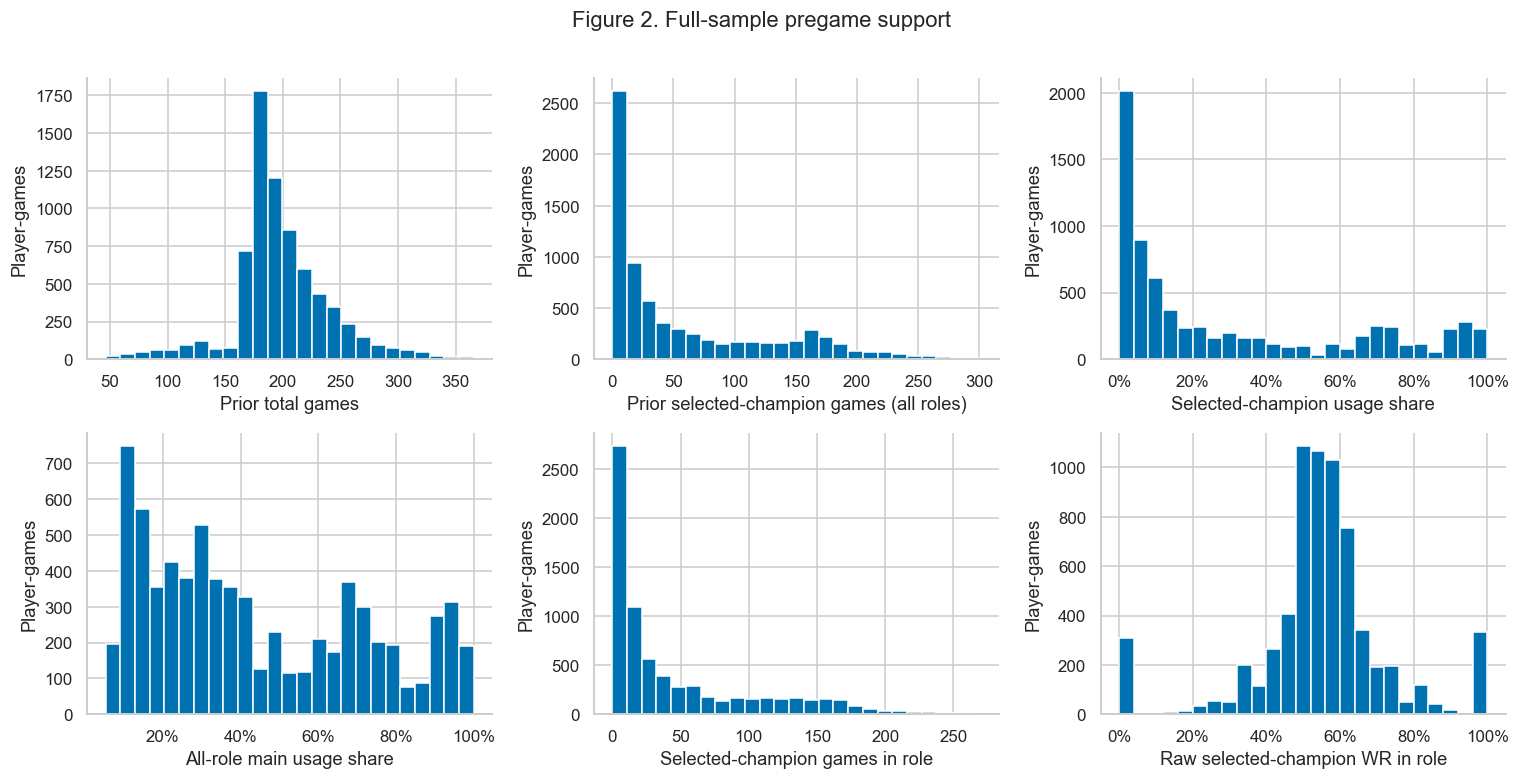

In [5]:
selected = candidates.loc[candidates.is_observed_pick,KEY+['same_role_prior_games','same_role_prior_wr','same_role_prior_wr_beta11']]
obs = obs.merge(selected,on=KEY,validate='one_to_one',how='left')
train = train.merge(selected,on=KEY,validate='one_to_one',how='left')
experience_cols = ['prior_total_games','prior_champion_games','prior_champion_wr',
    'prior_champion_usage_share','prior_main_champion_usage_share','same_role_prior_games','same_role_prior_wr']
show(obs[experience_cols].describe(percentiles=[.1,.25,.5,.75,.9]).T)
support = pd.DataFrame({
    'all_role_rows':obs.groupby('experience_group',observed=False).size(),
    'same_role_rows':obs.groupby(exp_bin(obs.same_role_prior_games),observed=False).size()})
show(support)
note(f'All-role chosen experience is zero in **{obs.prior_champion_games.eq(0).sum():,} / {len(obs):,} '
     f'({obs.prior_champion_games.eq(0).mean():.1%})** rows and below 5 in **{obs.prior_champion_games.lt(5).sum():,} '
     f'({obs.prior_champion_games.lt(5).mean():.1%})**. '
     f'Same-role experience is zero in {obs.same_role_prior_games.eq(0).sum():,} rows. '
     f'The all-role and same-role main identities differ where both are defined in {(obs.pregame_same_role_main_id.notna() & obs.prior_main_champion_id.ne(obs.pregame_same_role_main_id)).sum():,} rows '
     f'(same-role main missing in {obs.pregame_same_role_main_id.isna().sum()}).')
fig,axes=plt.subplots(2,3,figsize=(14,7))
for ax,col,label in zip(axes.flat,
    ['prior_total_games','prior_champion_games','prior_champion_usage_share','prior_main_champion_usage_share','same_role_prior_games','same_role_prior_wr'],
    ['Prior total games','Prior selected-champion games (all roles)','Selected-champion usage share','All-role main usage share','Selected-champion games in role','Raw selected-champion WR in role']):
    ax.hist(obs[col].dropna(),bins=25,color='#0072B2',edgecolor='white')
    ax.set(xlabel=label,ylabel='Player-games')
    if 'share' in col or '_wr' in col: ax.xaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle('Figure 2. Full-sample pregame support',y=1.01);done()

,rows,players,win_rate
experience_group,,,
0,295,99,39.0%
1–4,723,132,46.6%
5–14,942,121,50.6%
15–29,696,102,51.1%
30+,"2,430",141,51.9%


,rows,raw_available,raw_mean,beta11_mean,raw_extremes
experience_group,,,,,
0,408,0,—,50.0%,0
1–4,"1,038","1,038",50.3%,50.4%,541
5–14,"1,366","1,366",55.7%,54.6%,28
15–29,"1,007","1,007",55.7%,55.2%,0
30+,"3,408","3,408",54.7%,54.6%,0


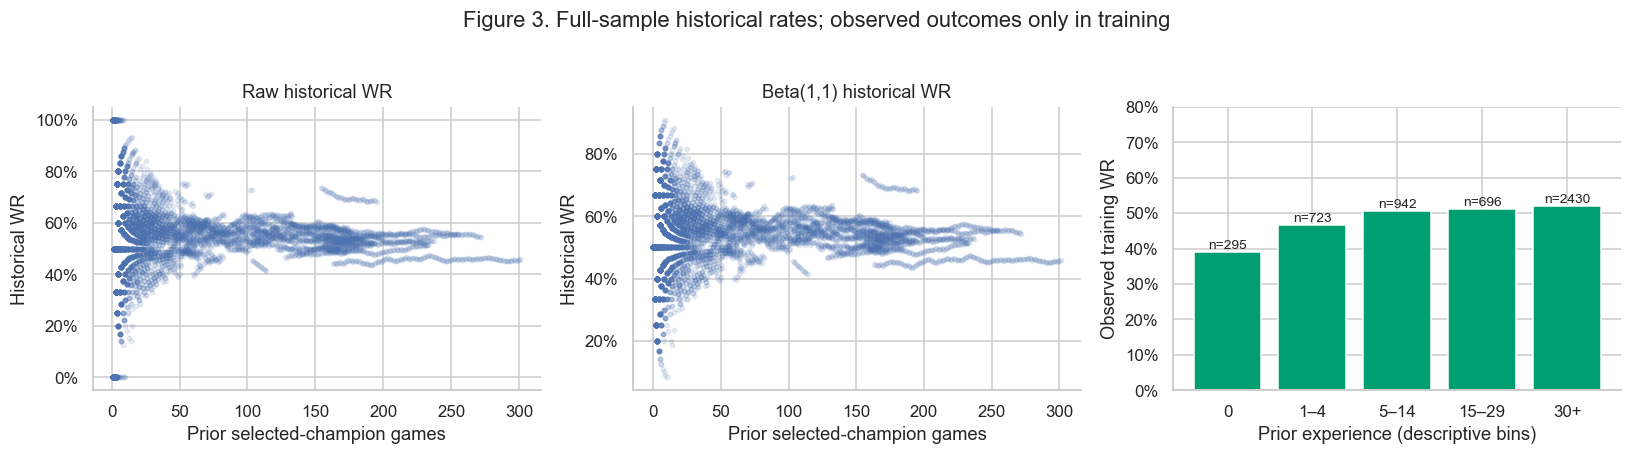

Raw rates use wins/games and are missing at zero. Beta(1,1) means use (wins+1)/(games+2). A 50% estimate at zero games is a prior assumption, not evidence of average skill. At 1–4 games, 541 of 1038 raw rates are 0% or 100%. The training outcome table shows denominators; these bins describe support and do not define eligibility. Historical win rate also reflects teammates, opponents, role, patch, selection and chance, beyond proficiency.

In training, observed WR rises from **39.0% (n=295)** with zero recorded champion games to **51.9% (n=2430)** at 30+. Intermediate groups are reported above. This pattern motivates retaining graded experience, but does not establish that additional practice caused the difference.

In [6]:
experience_outcomes = train.groupby('experience_group',observed=False).agg(
    rows=('win','size'),players=('puuid','nunique'),win_rate=('win','mean'))
show(experience_outcomes)
smoothing=obs.groupby('experience_group',observed=False).agg(rows=('puuid','size'),
    raw_available=('prior_champion_wr','count'),raw_mean=('prior_champion_wr','mean'),
    beta11_mean=('prior_champion_wr_beta11','mean'),
    raw_extremes=('prior_champion_wr',lambda x:x.isin([0,1]).sum()))
show(smoothing)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,c,label in zip(axes[:2],['prior_champion_wr','prior_champion_wr_beta11'],['Raw historical WR','Beta(1,1) historical WR']):
    ax.scatter(obs.prior_champion_games,obs[c],s=8,alpha=.12)
    ax.set(xlabel='Prior selected-champion games',ylabel='Historical WR',title=label)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[2].bar(EXP_LABELS,experience_outcomes.win_rate,color='#009E73')
for i,r in enumerate(experience_outcomes.itertuples()):
    axes[2].text(i,r.win_rate+.01,f'n={r.rows}',ha='center',fontsize=9)
axes[2].set(xlabel='Prior experience (descriptive bins)',ylabel='Observed training WR',ylim=(0,.8))
axes[2].yaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle('Figure 3. Full-sample historical rates; observed outcomes only in training',y=1.03);done()
note('Raw rates use wins/games and are missing at zero. Beta(1,1) means use (wins+1)/(games+2). '
     'A 50% estimate at zero games is a prior assumption, not evidence of average skill. '
     f'At 1–4 games, {smoothing.loc["1–4","raw_extremes"]:.0f} of {smoothing.loc["1–4","rows"]:.0f} raw rates are 0% or 100%. '
     'The training outcome table shows denominators; these bins describe support and do not define eligibility. '
     'Historical win rate also reflects teammates, opponents, role, patch, selection and chance, beyond proficiency.')
note(f'In training, observed WR rises from **{experience_outcomes.loc["0","win_rate"]:.1%} '
     f'(n={experience_outcomes.loc["0","rows"]})** with zero recorded champion games to '
     f'**{experience_outcomes.loc["30+","win_rate"]:.1%} (n={experience_outcomes.loc["30+","rows"]})** at 30+. '
     'Intermediate groups are reported above. This pattern motivates retaining graded experience, '
     'but does not establish that additional practice caused the difference.')

## 4. Population matchup strength and reliability

Full-sample distributions and support; training outcomes only in the grouped comparison. The raw rate is the population win percentage for that champion/opponent/role at Global Master+ on patch 16.19. Its probability form divides by 100. A raw rate over 50% includes champion strength and the benchmark's elevated tier average; it does not isolate counterpick advantage.

The saved **tier average** is the regional Master+ reference percentage. **Delta 2** is the website's “Counter Matchup Win Rate − Normalised Champions Win Rate in Matchup” statistic in percentage points. The derived **tier-centered rate** is raw percent − tier-average percent + 50. It is a separate, unclipped normalization and need not be a probability. None is silently substituted for another.

,Global observed
rows,7227.00
known_n,7227.00
missing_n,0.00
n_lt10,261.00
n_lt30,628.00
n_lt50,901.00
share_lt10_all_rows,0.04
share_lt30_all_rows,0.09
share_lt50_all_rows,0.12
median_n,449.00


,count,mean,std,min,25%,50%,75%,max
global_raw_matchup_winrate_pct,7227.00,52.52,7.39,0.00,50.00,52.55,55.02,100.00
global_raw_matchup_winrate_probability,7227.00,0.53,0.07,0.00,0.50,0.53,0.55,1.00
global_matchup_games,7227.00,963.15,1481.85,1.00,160.00,449.00,1088.50,9278.00
global_tier_average_winrate_pct,7227.00,52.45,0.00,52.45,52.45,52.45,52.45,52.45
global_website_delta2_pp,7227.00,0.05,7.04,-72.61,-1.99,0.06,2.05,61.62
global_derived_tier_centered_rate_pct,7227.00,50.07,7.39,-2.45,47.55,50.10,52.57,97.55


,rows,median_abs_from50,extreme_rate_share
sample_group,,,
<10,261,16.67,64.4%
10–29,367,10.00,47.1%
30–49,273,4.35,15.4%
50+,"6,326",3.09,3.1%


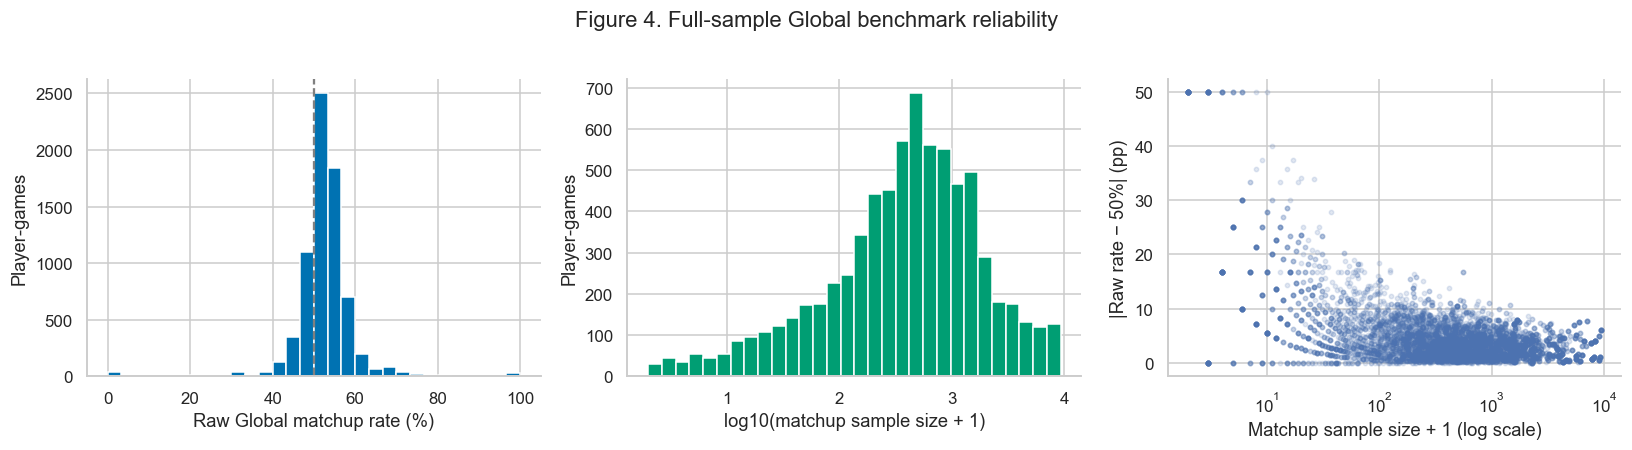

,rows,players,observed_wr,mean_population_pct,median_n
matchup_group,,,,,
<45%,275,100,36.7%,35.45,43.00
45–<50%,934,160,45.5%,48.15,439.00
50–<55%,"2,600",172,49.5%,52.46,642.00
55%+,"1,277",157,57.3%,59.48,241.00


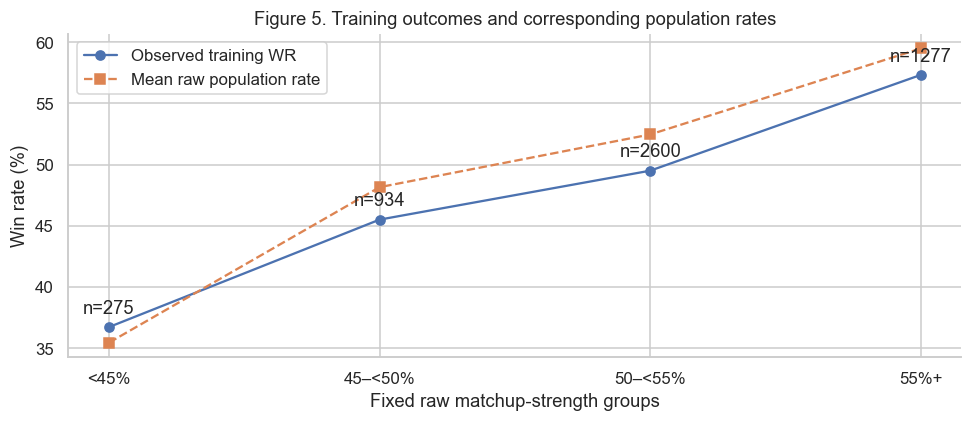

Global matchup sample size has median **449**. **628 rows (8.7%)** have fewer than 30 benchmark games. Rates outside 40–60% occur in 64.4% of rows with n<10 versus 3.1% with n≥50. These row-weighted summaries can repeat benchmark keys. Sample counts indicate reliability, not additional observed player-game outcomes. No missing rate is filled with 50%; Global and NA are never substituted.

In [7]:
def sample_coverage(frame, col):
    s=frame[col]
    return pd.Series({'rows':len(s),'known_n':s.notna().sum(),'missing_n':s.isna().sum(),
        'n_lt10':s.lt(10).sum(),'n_lt30':s.lt(30).sum(),'n_lt50':s.lt(50).sum(),
        'share_lt10_all_rows':s.lt(10).mean(),'share_lt30_all_rows':s.lt(30).mean(),
        'share_lt50_all_rows':s.lt(50).mean(),'median_n':s.median(),'p90_n':s.quantile(.9)})
show(sample_coverage(obs,N).to_frame('Global observed'))
show(obs[[RATE,'global_raw_matchup_winrate_probability',N,'global_tier_average_winrate_pct',
          'global_website_delta2_pp','global_derived_tier_centered_rate_pct']].describe().T)
obs['sample_group']=pd.cut(obs[N],[-1,9,29,49,np.inf],labels=['<10','10–29','30–49','50+'])
extremes=obs.groupby('sample_group',observed=False).agg(rows=('puuid','size'),
    median_abs_from50=(RATE,lambda s:(s-50).abs().median()),
    extreme_rate_share=(RATE,lambda s:((s<40)|(s>60)).mean()))
show(extremes)
fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].hist(obs[RATE],bins=30,color='#0072B2');axes[0].axvline(50,color='gray',ls='--')
axes[0].set(xlabel='Raw Global matchup rate (%)',ylabel='Player-games')
axes[1].hist(np.log10(obs[N]+1),bins=30,color='#009E73')
axes[1].set(xlabel='log10(matchup sample size + 1)',ylabel='Player-games')
axes[2].scatter(obs[N]+1,(obs[RATE]-50).abs(),s=8,alpha=.16)
axes[2].set(xscale='log',xlabel='Matchup sample size + 1 (log scale)',ylabel='|Raw rate − 50%| (pp)')
fig.suptitle('Figure 4. Full-sample Global benchmark reliability',y=1.02);done()
match_outcomes=train.groupby('matchup_group',observed=False).agg(rows=('win','size'),
    players=('puuid','nunique'),observed_wr=('win','mean'),mean_population_pct=(RATE,'mean'),median_n=(N,'median'))
show(match_outcomes)
fig,ax=plt.subplots(figsize=(9,4))
x=np.arange(len(match_outcomes))
ax.plot(x,100*match_outcomes.observed_wr,'o-',label='Observed training WR')
ax.plot(x,match_outcomes.mean_population_pct,'s--',label='Mean raw population rate')
for i,r in enumerate(match_outcomes.itertuples()): ax.annotate(f'n={r.rows}',(i,100*r.observed_wr),xytext=(0,9),textcoords='offset points',ha='center')
ax.set(xticks=x,xticklabels=MATCH_LABELS,xlabel='Fixed raw matchup-strength groups',ylabel='Win rate (%)',
       title='Figure 5. Training outcomes and corresponding population rates')
ax.legend();done()
note(f'Global matchup sample size has median **{obs[N].median():.0f}**. '
     f'**{obs[N].lt(30).sum():,} rows ({obs[N].lt(30).mean():.1%})** have fewer than 30 benchmark games. '
     f'Rates outside 40–60% occur in {extremes.loc["<10","extreme_rate_share"]:.1%} of rows with n<10 '
     f'versus {extremes.loc["50+","extreme_rate_share"]:.1%} with n≥50. '
     'These row-weighted summaries can repeat benchmark keys. Sample counts indicate reliability, not additional observed player-game outcomes. '
     'No missing rate is filled with 50%; Global and NA are never substituted.')

## 5. Proficiency and matchup together — completed training rows

Both weighting schemes below compare all-role main picks with off-main picks. The game-weighted difference weights prolific players more. The within-player comparison first computes each player's main-minus-off-main win-rate difference among players with both pick types, then averages players equally. Neither estimates the causal effect of switching champions; role, choice, opponent and experience differ. No independent-row significance tests are used.

,rows,players,win_rate
pick,,,
All-role main,"2,153",155,51.5%
Off-main,"2,933",166,49.0%


,comparison,difference_pp,support_players
0,Game-weighted main − off-main,2.55,177
1,Equal-player within-player main − off-main,4.30,144


Within-player per-group row counts (min / median):


pick,All-role main,Off-main
min,1.00,1.00
median,8.00,10.50


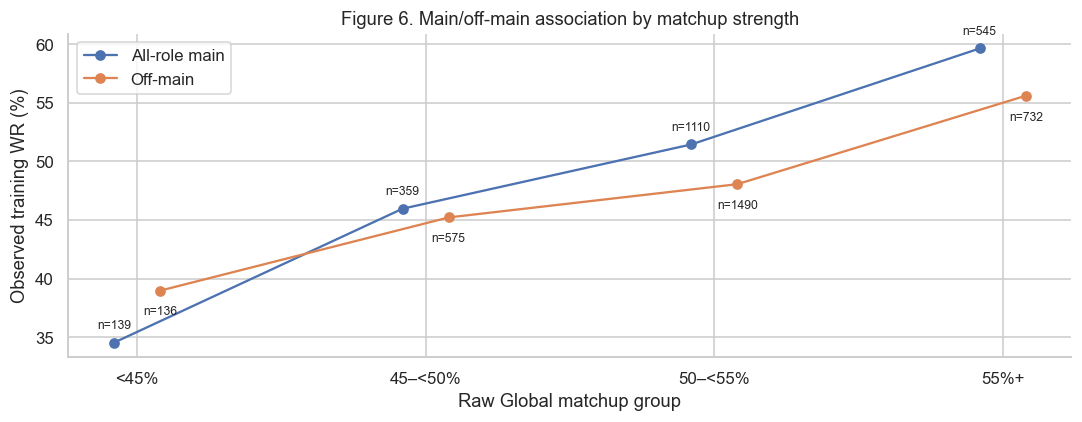

The game-weighted main-minus-off-main difference is **+2.55 pp**. Among **144 players** observed in both groups, the equal-player within-player difference is **+4.30 pp**. Different weighting and restriction to players with both choices can change the contrast. Sparse per-player groups remain noisy even in the equal-player summary.

In [8]:
central=train.groupby('pick').agg(rows=('win','size'),players=('puuid','nunique'),win_rate=('win','mean'))
show(central)
game_diff=central.loc['All-role main','win_rate']-central.loc['Off-main','win_rate']
within=train.groupby(['puuid','pick']).win.agg(['mean','size']).unstack('pick')
both=within['mean'].dropna()
within_diff=both['All-role main']-both['Off-main']
paired_counts=within['size'].loc[both.index]
show(pd.DataFrame({'comparison':['Game-weighted main − off-main','Equal-player within-player main − off-main'],
    'difference_pp':[100*game_diff,100*within_diff.mean()],
    'support_players':[train.puuid.nunique(),len(both)]}))
print('Within-player per-group row counts (min / median):')
show(paired_counts.agg(['min','median']))
by_main=train.groupby(['matchup_group','pick'],observed=False).agg(rows=('win','size'),
    players=('puuid','nunique'),wr=('win','mean'),mean_population_pct=(RATE,'mean'))
show(by_main)
fig,ax=plt.subplots(figsize=(10,4))
for label,offset in [('All-role main',-.08),('Off-main',.08)]:
    g=by_main.xs(label,level='pick').reindex(MATCH_LABELS)
    ax.plot(np.arange(4)+offset,100*g.wr,'o-',label=label)
    for i,r in enumerate(g.itertuples()):
        ax.annotate(f'n={r.rows}',(i+offset,100*r.wr),xytext=(0,9 if offset<0 else -16),textcoords='offset points',ha='center',fontsize=8)
ax.set(xticks=range(4),xticklabels=MATCH_LABELS,ylabel='Observed training WR (%)',xlabel='Raw Global matchup group',
       title='Figure 6. Main/off-main association by matchup strength');ax.legend();done()
note(f'The game-weighted main-minus-off-main difference is **{100*game_diff:+.2f} pp**. '
     f'Among **{len(both)} players** observed in both groups, the equal-player within-player difference is **{100*within_diff.mean():+.2f} pp**. '
     'Different weighting and restriction to players with both choices can change the contrast. '
     'Sparse per-player groups remain noisy even in the equal-player summary.')

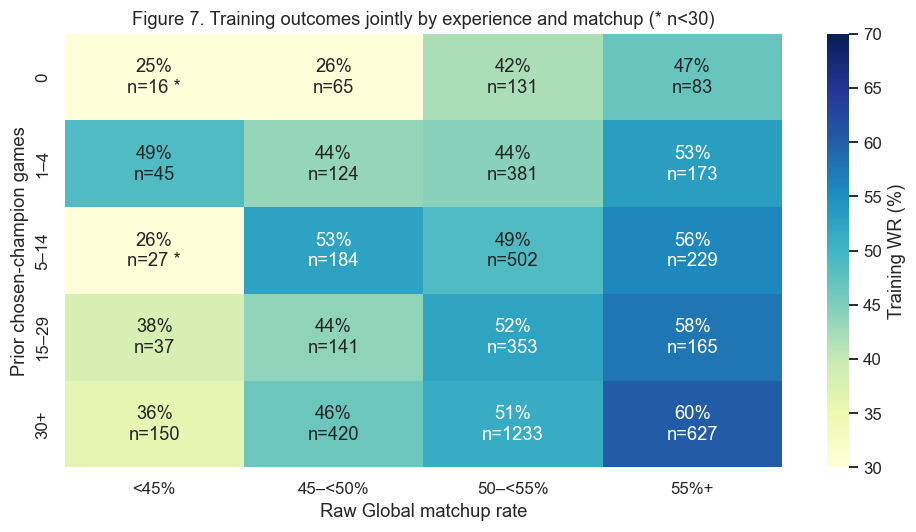

**2 of 20 cells** have fewer than 30 rows. Thirty is only a display warning, not an eligibility or modeling cutoff. Avoid reading a crossover threshold from this coarse, confounded table.

,rows,mean_matchup_pct,median_champion_games,median_same_role_games,mean_main_share
pick,,,,,
All-role main,"2,153",52.50,128.00,90.00,62.5%
Off-main,"2,933",52.52,8.00,7.00,32.1%


pick,All-role main,Off-main
lane,,
adc,0.28,0.22
jungle,0.15,0.19
mid,0.27,0.20
support,0.12,0.20
top,0.18,0.18


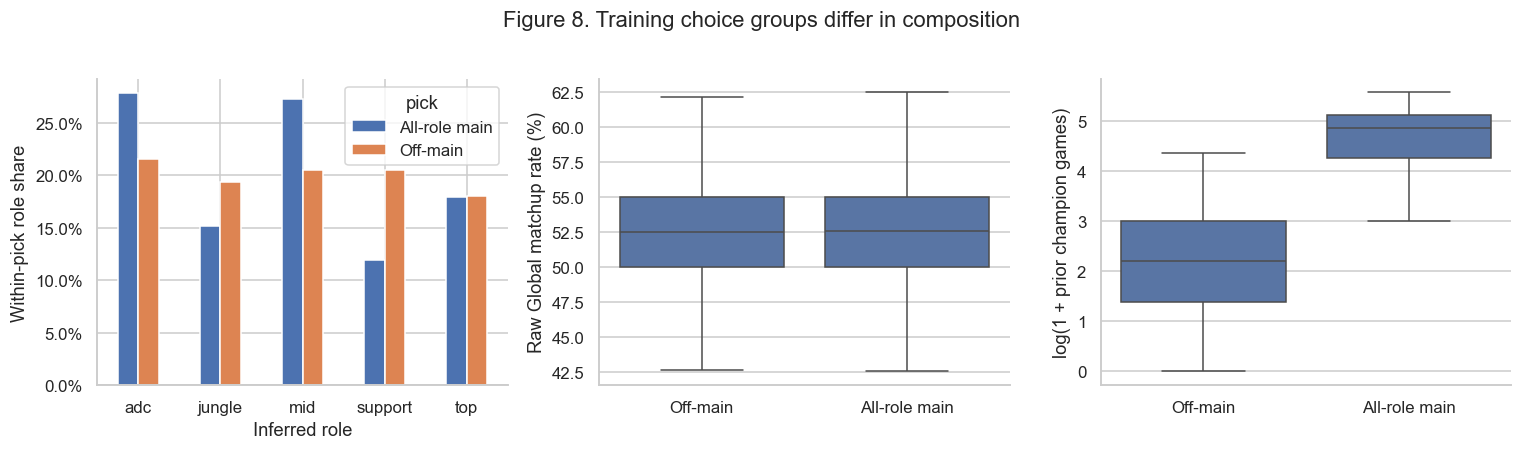

Main versus off-main median recorded champion experience is **128 versus 8 games**, whereas their mean raw Global rates are **52.50% versus 52.52%**. The aggregate outcome contrast therefore coexists with a large experience difference and similar average matchup rates; role composition and within-group differences still prevent a causal interpretation.

In [9]:
cross=train.groupby(['experience_group','matchup_group'],observed=False).agg(
    rows=('win','size'),players=('puuid','nunique'),wr=('win','mean'))
wr=cross.wr.unstack().reindex(index=EXP_LABELS,columns=MATCH_LABELS)
ct=cross.rows.unstack().reindex(index=EXP_LABELS,columns=MATCH_LABELS)
annotations=wr.copy().astype(object)
for i in wr.index:
    for j in wr.columns:
        annotations.loc[i,j]=f'{wr.loc[i,j]:.0%}\nn={ct.loc[i,j]:.0f}'+(' *' if ct.loc[i,j]<30 else '')
fig,ax=plt.subplots(figsize=(9,5))
sns.heatmap(wr*100,annot=annotations,fmt='',cmap='YlGnBu',vmin=30,vmax=70,ax=ax,cbar_kws={'label':'Training WR (%)'})
ax.set(xlabel='Raw Global matchup rate',ylabel='Prior chosen-champion games',
       title='Figure 7. Training outcomes jointly by experience and matchup (* n<30)');done()
show(cross)
note(f'**{int(ct.lt(30).sum().sum())} of {ct.size} cells** have fewer than 30 rows. '
     'Thirty is only a display warning, not an eligibility or modeling cutoff. Avoid reading a crossover threshold from this coarse, confounded table.')
composition=train.groupby('pick').agg(rows=('puuid','size'),mean_matchup_pct=(RATE,'mean'),
    median_champion_games=('prior_champion_games','median'),median_same_role_games=('same_role_prior_games','median'),
    mean_main_share=('prior_main_champion_usage_share','mean'))
show(composition)
lane_mix=pd.crosstab(train.lane,train.pick,normalize='columns')
show(lane_mix)
fig,axes=plt.subplots(1,3,figsize=(14,4))
lane_mix.plot.bar(ax=axes[0],rot=0);axes[0].set(ylabel='Within-pick role share',xlabel='Inferred role');axes[0].yaxis.set_major_formatter(PercentFormatter(1))
sns.boxplot(data=train,x='pick',y=RATE,ax=axes[1],showfliers=False)
axes[1].set(xlabel='',ylabel='Raw Global matchup rate (%)')
sns.boxplot(data=train.assign(log_experience=np.log1p(train.prior_champion_games)),x='pick',y='log_experience',ax=axes[2],showfliers=False)
axes[2].set(xlabel='',ylabel='log(1 + prior champion games)')
fig.suptitle('Figure 8. Training choice groups differ in composition',y=1.02);done()
note(f'Main versus off-main median recorded champion experience is '
     f'**{composition.loc["All-role main","median_champion_games"]:.0f} versus '
     f'{composition.loc["Off-main","median_champion_games"]:.0f} games**, whereas their mean raw Global rates are '
     f'**{composition.loc["All-role main","mean_matchup_pct"]:.2f}% versus '
     f'{composition.loc["Off-main","mean_matchup_pct"]:.2f}%**. '
     'The aggregate outcome contrast therefore coexists with a large experience difference and similar average matchup rates; '
     'role composition and within-group differences still prevent a causal interpretation.')

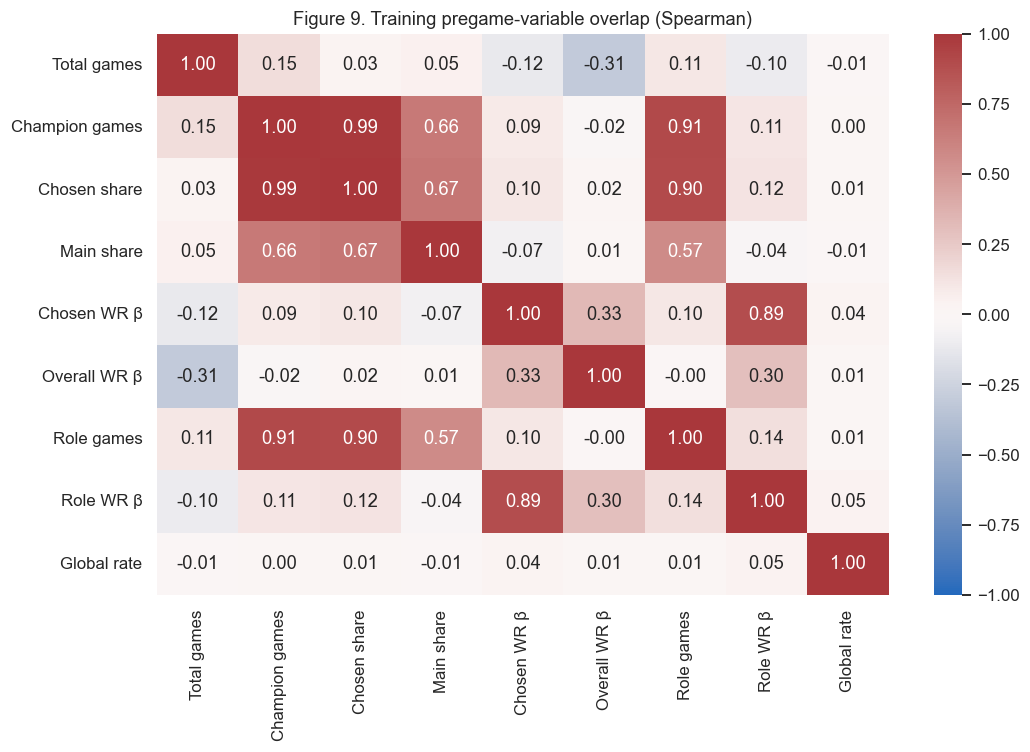

Counts and usage shares reuse denominators; all-role and same-role summaries also reuse many games. The largest correlations above motivate choosing a small representation rather than entering all variants together. Correlations do not establish interchangeability or predictive value.

In [10]:
corr_cols=['prior_total_games','prior_champion_games','prior_champion_usage_share',
    'prior_main_champion_usage_share','prior_champion_wr_beta11','prior_overall_wr_beta11',
    'same_role_prior_games','same_role_prior_wr_beta11',RATE]
labels=['Total games','Champion games','Chosen share','Main share','Chosen WR β','Overall WR β','Role games','Role WR β','Global rate']
corr=train[corr_cols].corr(method='spearman')
fig,ax=plt.subplots(figsize=(10,7))
sns.heatmap(corr.set_axis(labels).set_axis(labels,axis=1),annot=True,fmt='.2f',cmap='vlag',vmin=-1,vmax=1,ax=ax)
ax.set_title('Figure 9. Training pregame-variable overlap (Spearman)');done()
upper=corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack()
top_corr=upper.reindex(upper.abs().sort_values(ascending=False).index).head(5).rename('Spearman rho').to_frame()
show(top_corr)
note('Counts and usage shares reuse denominators; all-role and same-role summaries also reuse many games. '
     'The largest correlations above motivate choosing a small representation rather than entering all variants together. '
     'Correlations do not establish interchangeability or predictive value.')

## 6. Historically supported alternatives

Candidate coverage and pregame tradeoffs use primary-eligible targets across the full sample. Candidate comparisons linked to actual outcomes use only training targets, after aggregating to one row per target. Only actual picks have outcomes; unplayed candidates never receive their target's result.

An alternative is an unplayed saved candidate with prior same-role play, excluding the known opposing champion. The actual pick, all-role main and same-role main are distinct identities. Previous same-role use does not verify draft availability. Off-main does not automatically mean counterpick, and missing matchup rates do not mean a candidate is bad.

,count,mean,std,min,25%,50%,75%,max
n_alternatives,7227.00,10.55,9.05,0.00,4.00,8.00,15.00,41.00
valid_rate_share,6999.00,0.99,0.05,0.00,1.00,1.00,1.00,1.00
median_same_role_games,6999.00,3.83,6.30,1.00,2.00,2.00,4.00,160.00
median_matchup_n,6992.00,656.20,792.74,1.00,182.00,410.75,834.50,8177.00


,count,mean,std,min,25%,50%,75%,max
same_role_prior_games,76214.00,6.32,12.04,1.00,1.00,2.00,6.00,227.00
same_role_prior_wr,76214.00,0.45,0.35,0.00,0.00,0.50,0.67,1.00
same_role_prior_wr_beta11,76214.00,0.49,0.16,0.09,0.33,0.50,0.64,0.92
global_matchup_games,75831.00,755.51,1165.20,1.00,125.00,363.00,884.00,9278.00


Alternative candidate rows / primary targets: 76214 / 7227
Global valid alternative rates: 75831 / 76214


,Rate-covered alternative rows
rows,75831.00
known_n,75831.00
missing_n,0.00
n_lt10,2788.00
n_lt30,6880.00
n_lt50,10059.00
share_lt10_all_rows,0.04
share_lt30_all_rows,0.09
share_lt50_all_rows,0.13
median_n,363.00


,Share of targets with candidate identity present
main_available,0.80
same_role_main_available,0.97


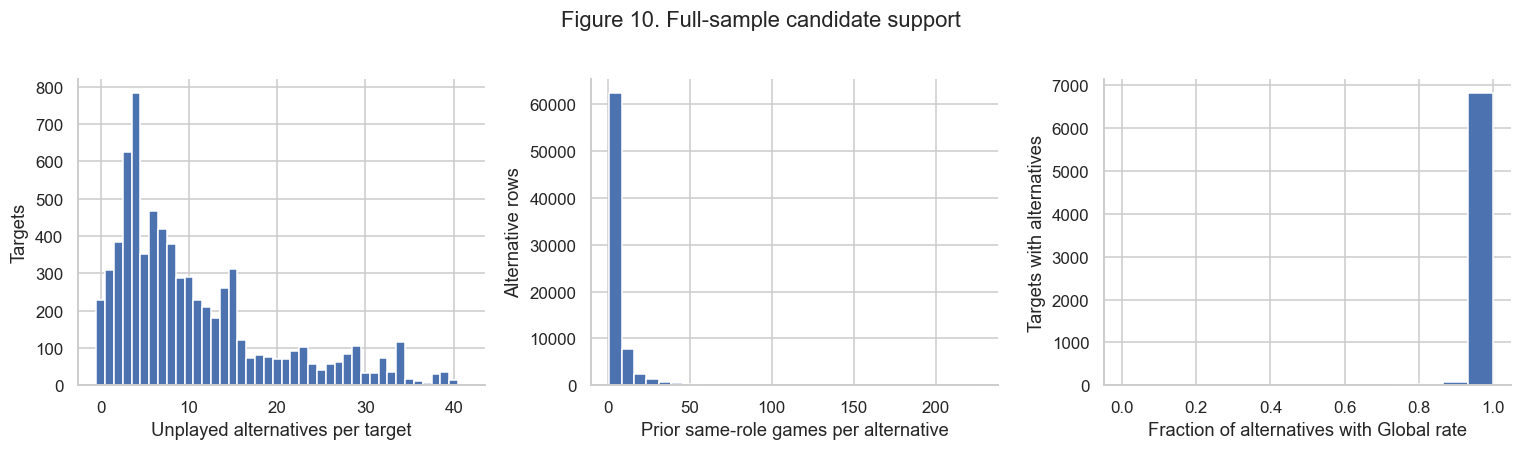

There are **83,523 candidate rows**, not that many observed outcomes. After restricting to 7,227 primary targets, 83,441 candidate rows remain, including 76,214 unplayed alternatives. **228 targets (3.2%)** have no alternatives. Global rates cover **99.5%** of alternative rows. Candidate-level distributions give prolific candidate sets more weight; the per-target table preserves the decision denominator.

In [11]:
eligible=candidates.merge(obs[KEY],on=KEY,how='inner',validate='many_to_one')
alts=eligible.loc[eligible.is_eligible_alternative].copy()
assert alts.observed_pick_win.isna().all()
alt_counts=alts.groupby(KEY).size().rename('n_alternatives')
targets=obs[KEY].merge(alt_counts,on=KEY,how='left',validate='one_to_one').fillna({'n_alternatives':0})
summary=alts.groupby(KEY).agg(valid_rate_share=('global_valid_rate','mean'),
    median_same_role_games=('same_role_prior_games','median'),median_matchup_n=(N,'median'))
targets=targets.merge(summary,on=KEY,how='left',validate='one_to_one')
show(targets[['n_alternatives','valid_rate_share','median_same_role_games','median_matchup_n']].describe().T)
show(alts[['same_role_prior_games','same_role_prior_wr','same_role_prior_wr_beta11',N]].describe().T)
print('Alternative candidate rows / primary targets:',len(alts), '/',len(targets))
print('Global valid alternative rates:',alts.global_valid_rate.sum(),'/',len(alts))
show(sample_coverage(alts.loc[alts.global_valid_rate],N).to_frame('Rate-covered alternative rows'))
identity=eligible.groupby(KEY).agg(main_available=('is_existing_pregame_main','any'),
                                  same_role_main_available=('is_pregame_same_role_main','any'))
show(identity.mean().rename('Share of targets with candidate identity present').to_frame())
fig,axes=plt.subplots(1,3,figsize=(14,4))
axes[0].hist(targets.n_alternatives,bins=np.arange(targets.n_alternatives.max()+2)-.5)
axes[0].set(xlabel='Unplayed alternatives per target',ylabel='Targets')
axes[1].hist(alts.same_role_prior_games,bins=30)
axes[1].set(xlabel='Prior same-role games per alternative',ylabel='Alternative rows')
axes[2].hist(targets.valid_rate_share.dropna(),bins=15)
axes[2].set(xlabel='Fraction of alternatives with Global rate',ylabel='Targets with alternatives')
fig.suptitle('Figure 10. Full-sample candidate support',y=1.02);done()
note(f'There are **{len(candidates):,} candidate rows**, not that many observed outcomes. '
     f'After restricting to {len(obs):,} primary targets, {len(eligible):,} candidate rows remain, '
     f'including {len(alts):,} unplayed alternatives. '
     f'**{targets.n_alternatives.eq(0).sum()} targets ({targets.n_alternatives.eq(0).mean():.1%})** have no alternatives. '
     f'Global rates cover **{alts.global_valid_rate.mean():.1%}** of alternative rows. '
     'Candidate-level distributions give prolific candidate sets more weight; the per-target table preserves the decision denominator.')

,count,mean,std,min,25%,50%,75%,max
experience_delta,61183.00,-45.21,41.24,-268.00,-59.00,-31.00,-18.00,39.00
proficiency_delta_pp,61183.00,-5.98,18.13,-63.60,-20.00,-6.25,7.65,51.19
matchup_delta_pp,61183.00,-0.37,9.48,-100.00,-3.81,-0.35,3.13,100.00


,count,mean,std,min,25%,50%,75%,max
paired_alternatives,5582.00,10.96,9.15,1.00,4.00,8.00,14.00,40.00
median_experience_delta,5582.00,-68.39,54.98,-267.50,-104.50,-53.00,-24.50,17.00
median_proficiency_delta_pp,5582.00,-7.22,11.98,-48.48,-15.64,-7.73,-0.00,50.00
median_matchup_delta_pp,5582.00,0.01,8.42,-100.00,-2.83,-0.30,2.63,83.34


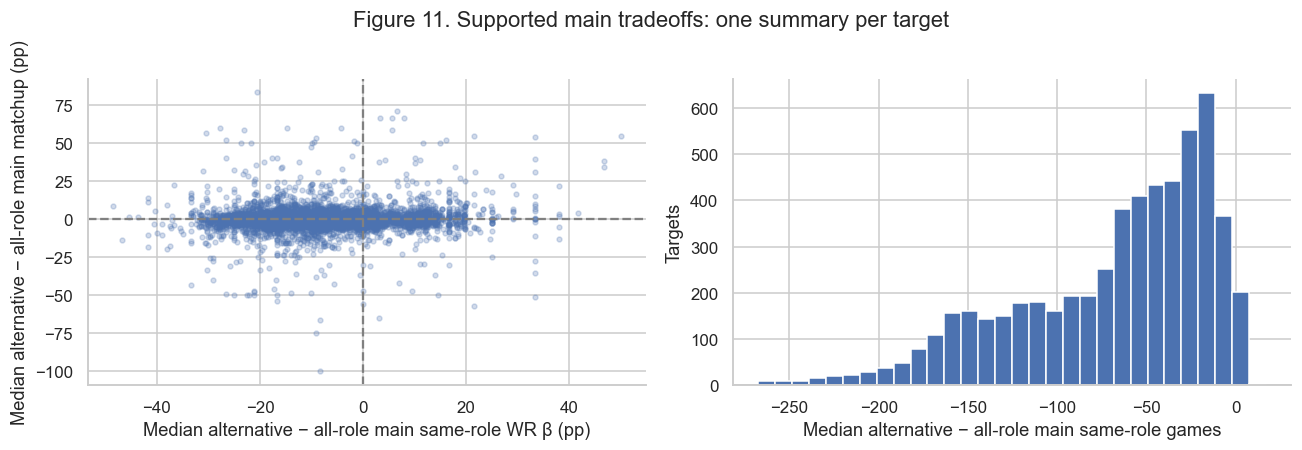

The illustrative paired restriction retains **5,582/7,227 targets** and 61,183 alternative pairs. Among retained targets, **4,698 (84.2%)** have at least one alternative with fewer same-role games but a higher raw population rate than the available all-role main. Using higher smoothed historical WR as the proficiency proxy instead, that tradeoff appears in **4,308 (77.2%)** targets. Recorded experience and historical WR represent different notions of proficiency. Main may be the actual pick or an unplayed candidate. No raw-rate maximization identifies a best counterpick; small samples can create large differences.

,targets,actual_pick_wr
candidate_support,,
"Alternatives, no supported main pair","1,026",47.9%
No alternatives,162,52.5%
Supported main comparison,"3,898",50.5%


The outcome-linked table contains **5,086 training targets exactly once each**. It describes actual-pick outcomes by candidate coverage, not outcomes from choosing alternatives. Coverage differences can reflect role and historical repertoire, so this is a support limitation, not a recommendation.

In [12]:
# Illustrative main comparison: main must be an actual saved candidate with same-role support.
# Retain distinct alternatives with a valid rate on both sides and >0 prior same-role games.
main_keys=eligible.loc[eligible.is_existing_pregame_main & eligible.same_role_prior_games.gt(0),KEY]
trade=alts.loc[~alts.is_existing_pregame_main & alts.global_valid_rate & alts.main_global_valid_rate
              & alts.main_same_role_prior_games.gt(0)].merge(main_keys,on=KEY,validate='many_to_one')
trade['experience_delta']=trade.same_role_prior_games-trade.main_same_role_prior_games
trade['proficiency_delta_pp']=trade.candidate_minus_main_same_role_prior_wr_beta11_pp
trade['matchup_delta_pp']=trade.candidate_minus_main_global_raw_matchup_pp
trade['main_more_experienced_but_weaker_matchup']=(trade.experience_delta.lt(0)&trade.matchup_delta_pp.gt(0))
trade['main_higher_beta_wr_but_weaker_matchup']=(trade.proficiency_delta_pp.lt(0)&trade.matchup_delta_pp.gt(0))
trade_summary=trade.groupby(KEY).agg(paired_alternatives=('candidate_champion_id','size'),
    median_experience_delta=('experience_delta','median'),median_proficiency_delta_pp=('proficiency_delta_pp','median'),
    median_matchup_delta_pp=('matchup_delta_pp','median'),
    experience_tradeoff_any=('main_more_experienced_but_weaker_matchup','any'),
    proficiency_tradeoff_any=('main_higher_beta_wr_but_weaker_matchup','any'))
show(trade[['experience_delta','proficiency_delta_pp','matchup_delta_pp']].describe().T)
show(trade_summary.describe().T)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(trade_summary.median_proficiency_delta_pp,trade_summary.median_matchup_delta_pp,s=10,alpha=.25)
axes[0].axvline(0,color='gray',ls='--');axes[0].axhline(0,color='gray',ls='--')
axes[0].set(xlabel='Median alternative − all-role main same-role WR β (pp)',
            ylabel='Median alternative − all-role main matchup (pp)')
axes[1].hist(trade_summary.median_experience_delta,bins=30)
axes[1].set(xlabel='Median alternative − all-role main same-role games',ylabel='Targets')
fig.suptitle('Figure 11. Supported main tradeoffs: one summary per target',y=1.02);done()
note(f'The illustrative paired restriction retains **{len(trade_summary):,}/{len(obs):,} targets** and {len(trade):,} alternative pairs. '
     f'Among retained targets, **{trade_summary.experience_tradeoff_any.sum():,} ({trade_summary.experience_tradeoff_any.mean():.1%})** '
     'have at least one alternative with fewer same-role games but a higher raw population rate than the available all-role main. '
     f'Using higher smoothed historical WR as the proficiency proxy instead, that tradeoff appears in '
     f'**{trade_summary.proficiency_tradeoff_any.sum():,} ({trade_summary.proficiency_tradeoff_any.mean():.1%})** targets. '
     'Recorded experience and historical WR represent different notions of proficiency. Main may be the actual pick or an unplayed candidate. '
     'No raw-rate maximization identifies a best counterpick; small samples can create large differences.')
# Outcome-linked candidate analysis: summaries are one row per target BEFORE the outcome join.
training_decisions=targets.merge(trade_summary,on=KEY,how='left',validate='one_to_one').merge(
    train[KEY+['win']],on=KEY,how='inner',validate='one_to_one')
training_decisions['candidate_support']=np.select([
    training_decisions.n_alternatives.eq(0),training_decisions.paired_alternatives.isna()],
    ['No alternatives','Alternatives, no supported main pair'],default='Supported main comparison')
show(training_decisions.groupby('candidate_support').agg(targets=('win','size'),actual_pick_wr=('win','mean')))
note(f'The outcome-linked table contains **{len(training_decisions):,} training targets exactly once each**. '
     'It describes actual-pick outcomes by candidate coverage, not outcomes from choosing alternatives. '
     'Coverage differences can reflect role and historical repertoire, so this is a support limitation, not a recommendation.')

## 7. Global versus NA sensitivity — identical paired rows, no outcomes

Paired comparisons use the saved 7,214-row regional subset. Global contains NA, so agreement is not independent replication. Global remains primary regardless of outcomes. Rates and sample sizes are compared without regional substitution or 50% imputation.

,Global,NA
rows,7214.00,7214.00
known_n,7214.00,7214.00
missing_n,0.00,0.00
n_lt10,252.00,1181.00
n_lt30,615.00,2795.00
n_lt50,888.00,3888.00
share_lt10_all_rows,0.03,0.16
share_lt30_all_rows,0.09,0.39
share_lt50_all_rows,0.12,0.54
median_n,450.00,44.00


,count,mean,std,min,25%,50%,75%,max
global_raw_matchup_winrate_pct,7214.00,52.53,7.28,0.00,50.00,52.55,55.02,100.00
na_raw_matchup_winrate_pct,7214.00,52.76,14.76,0.00,47.73,52.67,58.08,100.00
global_minus_na_pp,7214.00,-0.24,12.88,-75.00,-4.81,-0.08,4.37,84.00
global_matchup_games,7214.00,964.88,1482.63,1.00,160.00,450.00,1091.00,9278.00
na_matchup_games,7214.00,85.73,122.99,1.00,17.00,44.00,102.00,887.00


,rows,median_difference_pp,median_abs_difference_pp,mean_abs_difference_pp
na_n_group,,,,
<10,"1,181",0.00,16.67,20.70
10–29,"1,614",0.19,6.96,8.65
30–49,"1,093",0.15,5.38,6.05
50+,"3,326",-0.41,2.94,3.73


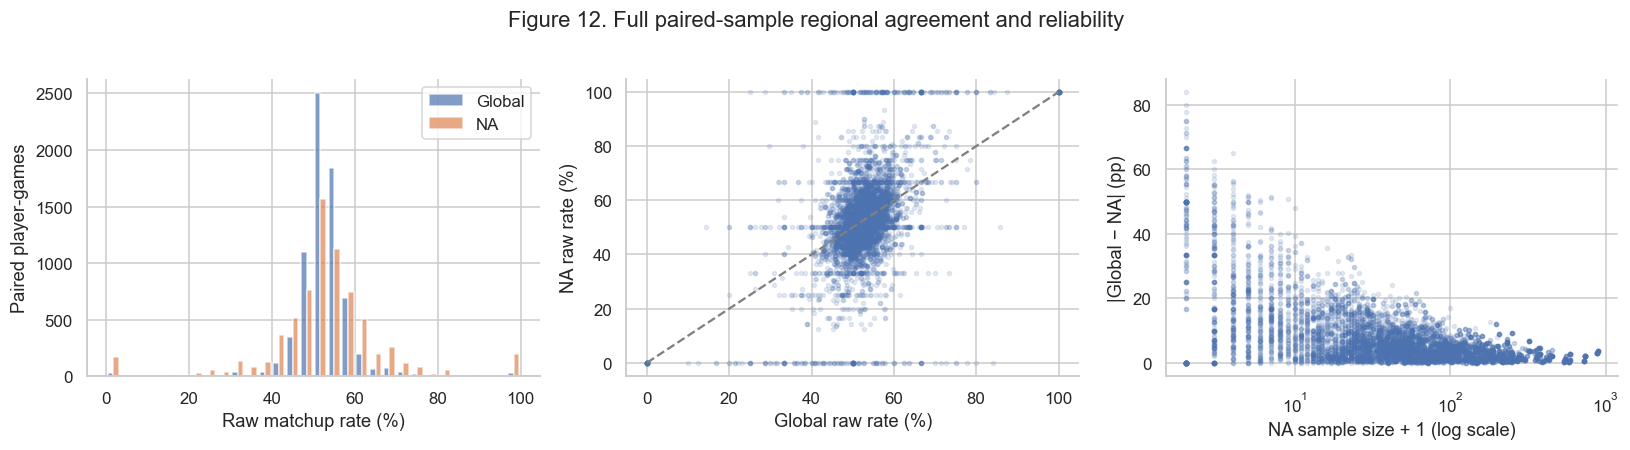

Primary targets absent from paired sensitivity: 13


,,Rows
lane,na_status,
jungle,not_published_in_table,2
mid,not_published_in_table,6
support,not_published_in_table,1
top,not_published_in_table,4


Paired coverage is **7,214/7,227 (99.82%)**. Global/NA raw-rate Pearson agreement is **0.488**, and the median absolute difference is **4.58 pp**. Median matchup n is **450 Global versus 44 NA**. The sample-stratified difference table shows where regional disagreement is most weakly supported. Repeated matchup keys mean these row-weighted agreement numbers are not independent-key evidence.

In [13]:
assert pd.MultiIndex.from_frame(paired[KEY]).isin(pd.MultiIndex.from_frame(obs[KEY])).all()
paired=paired.copy()
paired['global_minus_na_pp']=paired[RATE]-paired.na_raw_matchup_winrate_pct
paired['na_n_group']=pd.cut(paired.na_matchup_games,[-1,9,29,49,np.inf],labels=['<10','10–29','30–49','50+'])
show(pd.DataFrame({'Global':sample_coverage(paired,N),'NA':sample_coverage(paired,'na_matchup_games')}))
show(paired[[RATE,'na_raw_matchup_winrate_pct','global_minus_na_pp',N,'na_matchup_games']].describe().T)
regional_groups=paired.groupby('na_n_group',observed=False).agg(rows=('match_id','size'),
    median_difference_pp=('global_minus_na_pp','median'),
    median_abs_difference_pp=('global_minus_na_pp',lambda s:s.abs().median()),
    mean_abs_difference_pp=('global_minus_na_pp',lambda s:s.abs().mean()))
show(regional_groups)
regional_r=paired[[RATE,'na_raw_matchup_winrate_pct']].corr().iloc[0,1]
fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].hist([paired[RATE],paired.na_raw_matchup_winrate_pct],bins=np.linspace(0,100,31),label=['Global','NA'],alpha=.7)
axes[0].set(xlabel='Raw matchup rate (%)',ylabel='Paired player-games');axes[0].legend()
axes[1].scatter(paired[RATE],paired.na_raw_matchup_winrate_pct,s=7,alpha=.14)
axes[1].plot([0,100],[0,100],ls='--',color='gray');axes[1].set(xlabel='Global raw rate (%)',ylabel='NA raw rate (%)')
axes[2].scatter(paired.na_matchup_games+1,paired.global_minus_na_pp.abs(),s=7,alpha=.14)
axes[2].set(xscale='log',xlabel='NA sample size + 1 (log scale)',ylabel='|Global − NA| (pp)')
fig.suptitle('Figure 12. Full paired-sample regional agreement and reliability',y=1.02);done()
missing_paired=obs.loc[~pd.MultiIndex.from_frame(obs[KEY]).isin(pd.MultiIndex.from_frame(paired[KEY]))]
print('Primary targets absent from paired sensitivity:',len(missing_paired))
display(missing_paired.groupby(['lane','na_status'],dropna=False).size().rename('Rows').to_frame())
note(f'Paired coverage is **{len(paired):,}/{len(obs):,} ({len(paired)/len(obs):.2%})**. '
     f'Global/NA raw-rate Pearson agreement is **{regional_r:.3f}**, and the median absolute difference is '
     f'**{paired.global_minus_na_pp.abs().median():.2f} pp**. '
     f'Median matchup n is **{paired[N].median():.0f} Global versus {paired.na_matchup_games.median():.0f} NA**. '
     'The sample-stratified difference table shows where regional disagreement is most weakly supported. '
     'Repeated matchup keys mean these row-weighted agreement numbers are not independent-key evidence.')

## 8. What this means for modeling — proposals only

The next cells summarize the executed evidence and propose an explicit, small predictor list. No models are fitted, and no held-out outcome relationships are consulted.

In [14]:
player_support=train.groupby('puuid').agg(rows=('win','size'),wins=('win','sum'))
pc=train.groupby(['puuid','champion_id']).agg(rows=('win','size'),wins=('win','sum'))
show(pd.DataFrame([{'minimum_training_rows':k,'player_champion_groups':int(pc.rows.ge(k).sum()),
    'rows_in_those_groups':int(pc.loc[pc.rows.ge(k),'rows'].sum())} for k in [1,2,5,10,20]]))
print('Training players with both outcomes:',int((player_support.wins.gt(0)&player_support.wins.lt(player_support.rows)).sum()))
print('Training player–champion groups with both outcomes:',int((pc.wins.gt(0)&pc.wins.lt(pc.rows)).sum()))
a,b=top_corr.index[0]
note(f'**Executed descriptive findings.** Training main/off-main WRs are **{central.loc["All-role main","win_rate"]:.1%} / '
     f'{central.loc["Off-main","win_rate"]:.1%}**, a **{100*game_diff:+.2f} pp** game-weighted gap; '
     f'the equal-player gap is **{100*within_diff.mean():+.2f} pp** across {len(both)} players. '
     f'Training matchup-group WRs range from **{match_outcomes.observed_wr.min():.1%} to {match_outcomes.observed_wr.max():.1%}**; '
     'the earlier tables show their counts and population averages. These are descriptive associations, not isolated effects.')
note(f'**Sparse support and overlap.** {obs.prior_champion_games.lt(5).mean():.1%} of primary picks have fewer than five '
     f'recorded champion games; {obs[N].lt(30).mean():.1%} have fewer than 30 Global matchup games. '
     f'The supported candidate-main illustration covers {len(trade_summary)/len(obs):.1%} of targets. '
     f'The strongest displayed training correlation is `{a}` versus `{b}` (ρ={top_corr.iloc[0,0]:.2f}). '
     'Retain distinct concepts, and avoid entering every raw/smoothed/all-role/same-role variant together.')
note(f'**Hierarchical support.** Training has {len(player_support)} players, median {player_support.rows.median():.0f} rows per player, '
     f'and {len(pc)} player–champion groups. {pc.rows.eq(1).sum()} groups are singletons; '
     f'{pc.rows.ge(10).sum()} groups have at least ten rows. Player intercepts are plausible with partial pooling; '
     'player–champion effects need stronger pooling and a simpler player-only comparison. '
     'The group counts support estimation attempts, not a claim that all individual effects can be identified.')
note(f'**Experience and matchup gradients:** zero-history picks win {experience_outcomes.loc["0","win_rate"]:.1%} '
     f'of training games (n={experience_outcomes.loc["0","rows"]}), compared with '
     f'{experience_outcomes.loc["30+","win_rate"]:.1%} at 30+ prior games (n={experience_outcomes.loc["30+","rows"]}). '
     f'The <45% matchup group has WR {match_outcomes.iloc[0].observed_wr:.1%} (n={match_outcomes.iloc[0].rows:.0f}), '
     f'and the 55%+ group {match_outcomes.iloc[-1].observed_wr:.1%} (n={match_outcomes.iloc[-1].rows:.0f}). '
     'These coarse gradients motivate examining both signals; they do not identify a proficiency-versus-matchup switching point.')

,minimum_training_rows,player_champion_groups,rows_in_those_groups
0,1,"1,388","5,086"
1,2,618,"4,316"
2,5,237,"3,346"
3,10,124,"2,632"
4,20,37,"1,487"


Training players with both outcomes: 170
Training player–champion groups with both outcomes: 466


**Executed descriptive findings.** Training main/off-main WRs are **51.5% / 49.0%**, a **+2.55 pp** game-weighted gap; the equal-player gap is **+4.30 pp** across 144 players. Training matchup-group WRs range from **36.7% to 57.3%**; the earlier tables show their counts and population averages. These are descriptive associations, not isolated effects.

**Sparse support and overlap.** 20.0% of primary picks have fewer than five recorded champion games; 8.7% have fewer than 30 Global matchup games. The supported candidate-main illustration covers 77.2% of targets. The strongest displayed training correlation is `prior_champion_games` versus `prior_champion_usage_share` (ρ=0.99). Retain distinct concepts, and avoid entering every raw/smoothed/all-role/same-role variant together.

**Hierarchical support.** Training has 177 players, median 19 rows per player, and 1388 player–champion groups. 770 groups are singletons; 124 groups have at least ten rows. Player intercepts are plausible with partial pooling; player–champion effects need stronger pooling and a simpler player-only comparison. The group counts support estimation attempts, not a claim that all individual effects can be identified.

**Experience and matchup gradients:** zero-history picks win 39.0% of training games (n=295), compared with 51.9% at 30+ prior games (n=2430). The <45% matchup group has WR 36.7% (n=275), and the 55%+ group 57.3% (n=1277). These coarse gradients motivate examining both signals; they do not identify a proficiency-versus-matchup switching point.

In [15]:
predictors=pd.DataFrame([
 ('global_raw_matchup_winrate_probability','Primary population matchup term; center; consider external-estimate uncertainty'),
 ('prior_champion_games','Use log1p count to represent experience with diminishing increments, including zero'),
 ('prior_total_games','Use log1p count to distinguish overall recorded-history depth'),
 ('prior_champion_wr_beta11','Smoothed historical proficiency; interpret with count, not as pure skill'),
 ('prior_main_champion_usage_share','Continuous specialization; no OTP threshold'),
 ('is_main_champion','Actual pick is the existing all-role main'),
 ('side','Known team side, categorical control'),
 ('lane','Categorical role control only with defensible prospective pregame role assignment')
],columns=['Proposed baseline predictor','Treatment / interpretation'])
display(predictors)
note('**Baseline logistic proposal:** use the explicit terms above, fitting any scaling/transformation parameters on training only. '
     '**Hierarchical logistic proposal:** use the same fixed terms plus a player intercept, then consider a partially pooled '
     'player–champion intercept if support and identifiability allow. `puuid` is a grouping identity, not a numeric predictor; '
     '`match_id` handles shared-match dependence (grouped resampling or an appropriate dependence structure). '
     'A player-only hierarchy is an essential simpler comparison. A match effect cannot be estimated for a new match from its outcome.')
note('**Pre-specified refinements to consider:** matchup × log1p champion experience or matchup × main-pick status can address '
     'the substantive question, but sparse crossed cells argue against fitting both freely at first. '
     'Treat champion WR and its support jointly; Beta(1,1) smoothing is minimal shrinkage, not a fitted skill model. '
     'Avoid adding chosen usage share alongside chosen count and total count without a reason. '
     'Same-role experience/WR can replace all-role measures in a labeled sensitivity, rather than adding overlapping copies. '
     'A reliability-aware sensitivity should shrink external rates or model their uncertainty; arbitrary deletion of small samples is not the default.')
note('**Keep these sensitivities:** paired Global/NA on identical rows; documented raw versus tier-centered/Delta2 specifications '
     '(with their distinct interpretation and availability); sensitivity to external matchup sample support; all-role versus same-role '
     'proficiency/main definitions; game-weighted versus equal-player descriptions; player-only versus player–champion pooling. '
     'Keep candidate summaries descriptive until draft availability and counterfactual assumptions have a defensible design. '
     'Do not choose a benchmark or cutoff for a favorable observed result.')
note('**Predictor exclusions and limits:** `win` is the response. Current-game outcomes, postgame statistics, `end_timestamp`, '
     'latest-completion fields, collection/coverage flags, sampling/rank metadata, audit/status/source fields and legacy `is_otp` '
     'do not enter the proposed predictor list. Role/opponent are inferred from completed matches and need prospective justification. '
     'Patch-wide matchup statistics are retrospective: even time-safe player histories do not make these benchmarks information '
     'available at each kickoff. Historical WR is affected by selection and game context as well as skill. '
     'This EDA establishes neither causal switching effects nor proven counterfactual recommendations.')
note('**Evaluation protocol:** preserve the exact chronological cutoffs and whole-match completion purges. '
     'Chronological evaluation primarily measures later performance of known players; player-held-out generalization requires '
     'a separate design. Under an explicit sequential protocol, player features may update from earlier games only after those '
     'games complete, including earlier validation/test games. Fitted model parameters and fitted transformations remain frozen '
     'during evaluation. No held-out outcome performance was inspected here.')
print('Completed: descriptive EDA only; 12 inline figures; no models, source writes, or external requests.')

,Proposed baseline predictor,Treatment / interpretation
0,global_raw_matchup_winrate_probability,Primary population matchup term; center; consi...
1,prior_champion_games,Use log1p count to represent experience with d...
2,prior_total_games,Use log1p count to distinguish overall recorde...
3,prior_champion_wr_beta11,Smoothed historical proficiency; interpret wit...
4,prior_main_champion_usage_share,Continuous specialization; no OTP threshold
5,is_main_champion,Actual pick is the existing all-role main
6,side,"Known team side, categorical control"
7,lane,Categorical role control only with defensible ...


**Baseline logistic proposal:** use the explicit terms above, fitting any scaling/transformation parameters on training only. **Hierarchical logistic proposal:** use the same fixed terms plus a player intercept, then consider a partially pooled player–champion intercept if support and identifiability allow. `puuid` is a grouping identity, not a numeric predictor; `match_id` handles shared-match dependence (grouped resampling or an appropriate dependence structure). A player-only hierarchy is an essential simpler comparison. A match effect cannot be estimated for a new match from its outcome.

**Pre-specified refinements to consider:** matchup × log1p champion experience or matchup × main-pick status can address the substantive question, but sparse crossed cells argue against fitting both freely at first. Treat champion WR and its support jointly; Beta(1,1) smoothing is minimal shrinkage, not a fitted skill model. Avoid adding chosen usage share alongside chosen count and total count without a reason. Same-role experience/WR can replace all-role measures in a labeled sensitivity, rather than adding overlapping copies. A reliability-aware sensitivity should shrink external rates or model their uncertainty; arbitrary deletion of small samples is not the default.

**Keep these sensitivities:** paired Global/NA on identical rows; documented raw versus tier-centered/Delta2 specifications (with their distinct interpretation and availability); sensitivity to external matchup sample support; all-role versus same-role proficiency/main definitions; game-weighted versus equal-player descriptions; player-only versus player–champion pooling. Keep candidate summaries descriptive until draft availability and counterfactual assumptions have a defensible design. Do not choose a benchmark or cutoff for a favorable observed result.

**Predictor exclusions and limits:** `win` is the response. Current-game outcomes, postgame statistics, `end_timestamp`, latest-completion fields, collection/coverage flags, sampling/rank metadata, audit/status/source fields and legacy `is_otp` do not enter the proposed predictor list. Role/opponent are inferred from completed matches and need prospective justification. Patch-wide matchup statistics are retrospective: even time-safe player histories do not make these benchmarks information available at each kickoff. Historical WR is affected by selection and game context as well as skill. This EDA establishes neither causal switching effects nor proven counterfactual recommendations.

**Evaluation protocol:** preserve the exact chronological cutoffs and whole-match completion purges. Chronological evaluation primarily measures later performance of known players; player-held-out generalization requires a separate design. Under an explicit sequential protocol, player features may update from earlier games only after those games complete, including earlier validation/test games. Fitted model parameters and fitted transformations remain frozen during evaluation. No held-out outcome performance was inspected here.

Completed: descriptive EDA only; 12 inline figures; no models, source writes, or external requests.


## Champion specialization versus expected performance

**Scope: completed training-period primary Global rows**, with the existing chronological cutoff and whole-match completion purge. The x-axis label **OTP Rate** refers here to strictly pregame `prior_champion_usage_share`: prior games on the **champion selected now** divided by all prior collected games. It is not the main champion's share when another champion is picked. Zero-usage picks stay in the first group; no OTP eligibility threshold is applied. Groups span 10 percentage points; the final 90–100% group includes 100%.

Here, **expected** means the retrospective patch-16.19 Global Master+ raw matchup benchmark for the observed pick and opponent. It is not an individualized model prediction or a strictly contemporaneous kickoff forecast. Observed and expected rates within each group use exactly the same rows. Missing benchmarks are never filled with 50%; any missing usage or rate coverage is reported explicitly.

,field,units,definition
581,prior_champion_usage_share,proportion 0–1,Prior chosen-champion games / all prior games.
679,global_raw_matchup_winrate_pct,percent 0–100,GLOBAL retrospective Master+ patch-16.19: Raw ...
709,global_raw_matchup_winrate_probability,probability 0–1,GLOBAL retrospective Master+ patch-16.19: Vali...


Units confirmed: usage and raw matchup probability are 0–1; raw matchup percent is 0–100.
Training rows: 5,086; missing usage: 0; missing rate pair: 0; rows compared: 5,086.


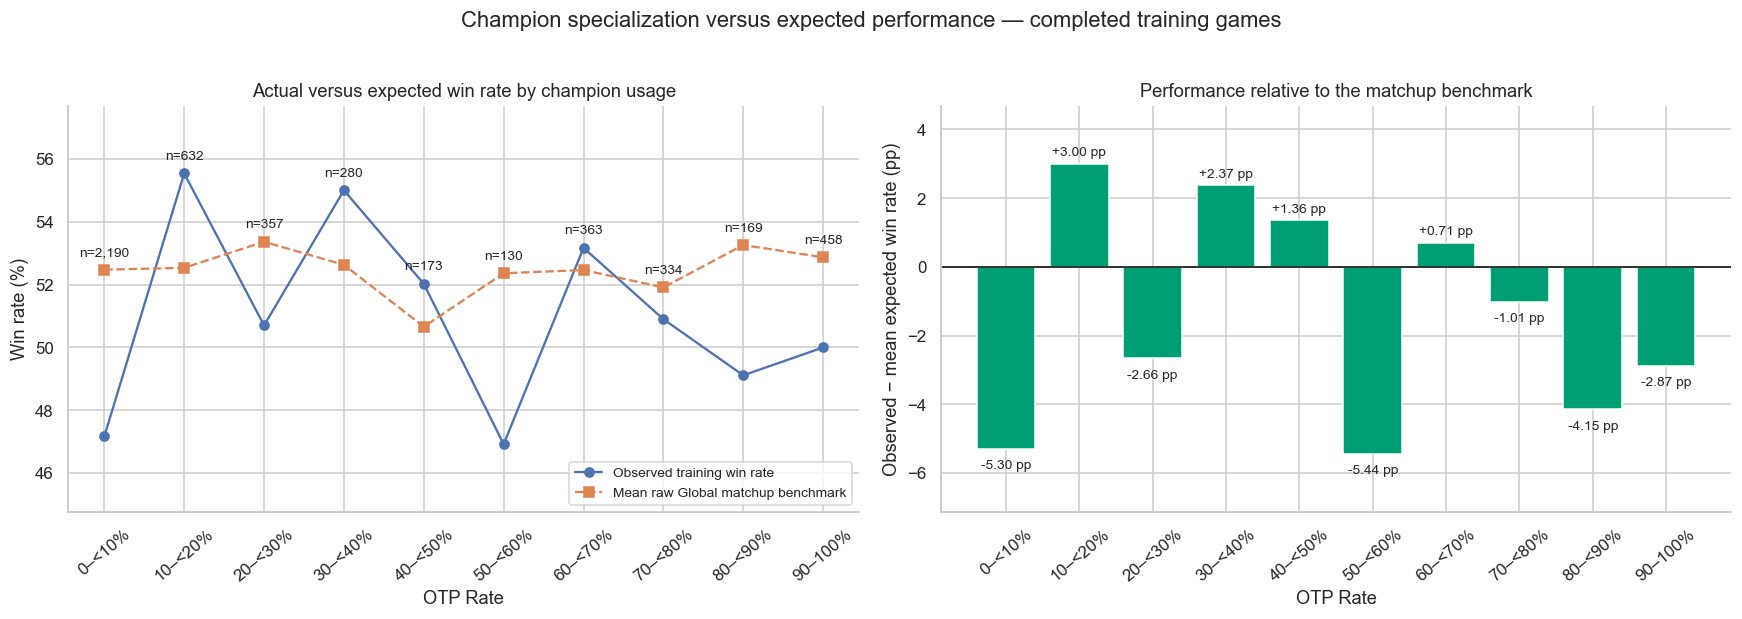

OTP Rate,Observations,Unique players,Observed win rate,Mean expected matchup win rate,Difference (pp)
0–<10%,"2,190",158,47.17%,52.47%,-5.30
10–<20%,632,89,55.54%,52.53%,+3.00
20–<30%,357,38,50.70%,53.36%,-2.66
30–<40%,280,33,55.00%,52.63%,+2.37
40–<50%,173,17,52.02%,50.66%,+1.36
50–<60%,130,16,46.92%,52.36%,-5.44
60–<70%,363,21,53.17%,52.46%,+0.71
70–<80%,334,15,50.90%,51.91%,-1.01
80–<90%,169,13,49.11%,53.26%,-4.15
90–100%,458,19,50.00%,52.87%,-2.87


In [16]:
# Inspect the saved units before arithmetic; no inferred percent/probability conversion.
usage_probability_col = 'global_raw_matchup_winrate_probability'
usage_raw_pct_col = 'global_raw_matchup_winrate_pct'
display(dictionary.loc[
    dictionary.dataset.eq('observed_global_analysis') & dictionary.field.isin([
        'prior_champion_usage_share', usage_probability_col, usage_raw_pct_col]),
    ['field','units','definition']])
usage_frame = train[KEY + ['win','prior_champion_usage_share',
                         usage_probability_col,usage_raw_pct_col]].copy()
usage_known = usage_frame.prior_champion_usage_share.notna()
usage_rate_known = usage_frame[[usage_probability_col,usage_raw_pct_col]].notna().all(axis=1)
assert usage_frame.loc[usage_known,'prior_champion_usage_share'].between(0,1).all()
assert usage_frame.loc[usage_rate_known,usage_probability_col].between(0,1).all()
assert usage_frame.loc[usage_rate_known,usage_raw_pct_col].between(0,100).all()
assert np.allclose(usage_frame.loc[usage_rate_known,usage_probability_col],
                   usage_frame.loc[usage_rate_known,usage_raw_pct_col] / 100)
print('Units confirmed: usage and raw matchup probability are 0–1; raw matchup percent is 0–100.')
print(f'Training rows: {len(usage_frame):,}; missing usage: {(~usage_known).sum():,}; '
      f'missing rate pair: {(~usage_rate_known).sum():,}; '
      f'rows compared: {(usage_known & usage_rate_known).sum():,}.')
usage_comparison = usage_frame.loc[usage_known & usage_rate_known].copy()
usage_labels = [f'{lower}–<{lower+10}%' for lower in range(0,90,10)] + ['90–100%']
usage_comparison['usage_group'] = pd.cut(
    usage_comparison.prior_champion_usage_share,
    bins=[v/10 for v in range(10)] + [np.nextafter(1.,np.inf)],right=False,labels=usage_labels)
assert usage_comparison.usage_group.notna().all()
usage_summary = usage_comparison.groupby('usage_group',observed=False).agg(
    observations=('win','size'),unique_players=('puuid','nunique'),
    observed_win_rate=('win','mean'),
    mean_expected_matchup_win_rate=(usage_probability_col,'mean'))
usage_summary['difference_pp'] = 100 * (
    usage_summary.observed_win_rate - usage_summary.mean_expected_matchup_win_rate)
assert usage_summary.observations.sum() == len(usage_comparison)

fig,axes = plt.subplots(1,2,figsize=(16,5.5))
usage_x = np.arange(len(usage_labels))
axes[0].plot(usage_x,100*usage_summary.observed_win_rate,'o-',label='Observed training win rate')
axes[0].plot(usage_x,100*usage_summary.mean_expected_matchup_win_rate,'s--',
             label='Mean raw Global matchup benchmark')
for x,row in zip(usage_x,usage_summary.itertuples()):
    height = 100*max(row.observed_win_rate,row.mean_expected_matchup_win_rate)
    axes[0].annotate(f'n={row.observations:,}',(x,height),xytext=(0,9),
                     textcoords='offset points',ha='center',fontsize=9)
axes[0].set(title='Actual versus expected win rate by champion usage',ylabel='Win rate (%)')
axes[0].margins(y=.25)
axes[0].legend(loc='lower right',fontsize=9)
axes[1].bar(usage_x,usage_summary.difference_pp,color='#009E73')
axes[1].axhline(0,color='black',linewidth=1)
axes[1].set(title='Performance relative to the matchup benchmark',
            ylabel='Observed − mean expected win rate (pp)')
for x,row in zip(usage_x,usage_summary.itertuples()):
    axes[1].annotate(f'{row.difference_pp:+.2f} pp',(x,row.difference_pp),
                     xytext=(0,5 if row.difference_pp>=0 else -13),
                     textcoords='offset points',ha='center',fontsize=9)
axes[1].margins(y=.2)
for ax in axes:
    ax.set(xticks=usage_x,xticklabels=usage_labels,
           xlabel='OTP Rate')
    ax.tick_params(axis='x',labelrotation=40)
fig.suptitle('Champion specialization versus expected performance — completed training games',y=1.02)
done()
usage_table = usage_summary.reset_index().rename(columns={
    'usage_group':'OTP Rate','observations':'Observations','unique_players':'Unique players',
    'observed_win_rate':'Observed win rate','mean_expected_matchup_win_rate':'Mean expected matchup win rate',
    'difference_pp':'Difference (pp)'})
display(usage_table.style.format({
    'Observations':'{:,}','Unique players':'{:,}',
    'Observed win rate':'{:.2%}','Mean expected matchup win rate':'{:.2%}',
    'Difference (pp)':'{:+.2f}'},na_rep='—').hide(axis='index'))

In [17]:
usage_first,usage_last = usage_summary.iloc[0],usage_summary.iloc[-1]
usage_positive = usage_summary.index[usage_summary.difference_pp.gt(0)].tolist()
note(f'Across **{len(usage_comparison):,} completed training observations**, the 0–<10% OTP Rate group has '
     f'**{usage_first.observed_win_rate:.2%}** observed WR versus **{usage_first.mean_expected_matchup_win_rate:.2%}** '
     f'expected (**{usage_first.difference_pp:+.2f} pp**, n={int(usage_first.observations):,}; '
     f'{int(usage_first.unique_players)} players). The 90–100% group has '
     f'**{usage_last.observed_win_rate:.2%}** observed versus **{usage_last.mean_expected_matchup_win_rate:.2%}** '
     f'expected (**{usage_last.difference_pp:+.2f} pp**, n={int(usage_last.observations):,}; '
     f'{int(usage_last.unique_players)} players). '
     f'Groups with positive benchmark differences: **{", ".join(usage_positive) if usage_positive else "none"}**. '
     'The complete group counts and contrasts are in the table above.')
note('Positive differences indicate descriptive outperformance of the retrospective Global Master+ matchup benchmark. '
     'Differences do not prove a causal specialization benefit or establish a usage threshold. '
     'The benchmark does not adjust for the individual player or all differences in champion, role, opponent and pick selection. '
     'Players repeat within and across groups and some matches are shared; the plotted contrasts have no independent-row '
     'significance interpretation. Usage bins organize the description and do not define OTP eligibility.')

Across **5,086 completed training observations**, the 0–<10% OTP Rate group has **47.17%** observed WR versus **52.47%** expected (**-5.30 pp**, n=2,190; 158 players). The 90–100% group has **50.00%** observed versus **52.87%** expected (**-2.87 pp**, n=458; 19 players). Groups with positive benchmark differences: **10–<20%, 30–<40%, 40–<50%, 60–<70%**. The complete group counts and contrasts are in the table above.

Positive differences indicate descriptive outperformance of the retrospective Global Master+ matchup benchmark. Differences do not prove a causal specialization benefit or establish a usage threshold. The benchmark does not adjust for the individual player or all differences in champion, role, opponent and pick selection. Players repeat within and across groups and some matches are shared; the plotted contrasts have no independent-row significance interpretation. Usage bins organize the description and do not define OTP eligibility.

## Champion specialization against Global and NA Master+ matchup benchmarks

**Scope:** the saved final paired-region dataset, restricted to the same completed training targets used above. The exact chronological boundaries and whole-match completion purge are unchanged. Both benchmarks and observed outcomes are compared on identical player-games. Global remains primary; NA is a sensitivity analysis. The strictly pregame usage share refers to the champion selected in that game, including off-main and zero-usage picks.

“Expected” is the retrospective patch-16.19 Master+ raw matchup benchmark, not an individualized model prediction or information necessarily available at kickoff. Missing rates are neither filled nor substituted between regions. The dictionary inspection and coverage counts below precede arithmetic.

,field,units,definition
850,prior_champion_usage_share,proportion 0–1,Prior chosen-champion games / all prior games.
948,global_raw_matchup_winrate_pct,percent 0–100,GLOBAL retrospective Master+ patch-16.19: Raw ...
978,global_raw_matchup_winrate_probability,probability 0–1,GLOBAL retrospective Master+ patch-16.19: Vali...
995,na_matchup_games,games,NA retrospective Master+ patch-16.19: Publishe...
1008,na_raw_matchup_winrate_pct,percent 0–100,NA retrospective Master+ patch-16.19: Raw obse...
1038,na_raw_matchup_winrate_probability,probability 0–1,NA retrospective Master+ patch-16.19: Valid ve...


Units checked: usage/probabilities 0–1; raw rate fields 0–100; matchup counts in games.


,Coverage stage,Observations
0,Completed primary Global training targets,5086
1,Training targets present in paired snapshot,5077
2,Absent from paired snapshot,9
3,Additional paired rows missing either benchmark,0
4,Total excluded by requiring both benchmarks,9
5,Additional missing usage among both-rate rows,0
6,Identical observations compared,5077


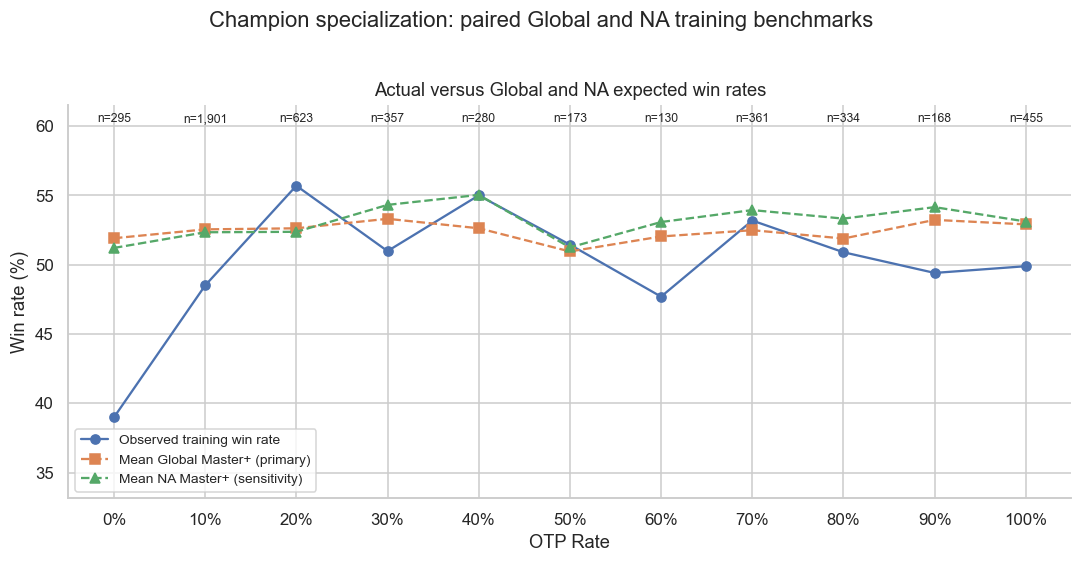

**Bin convention:** 0% is a separate group containing exactly zero recorded selected-champion usage. The remaining labels are upper endpoints: 10% means >0–10%, 20% means >10–20%, and so on through 100% (>90–100%). The final group includes 100%. Empty bins retain their position and appear as gaps. These are the selected champion’s pregame usage shares, not exact OTP eligibility thresholds.

Usage-bin label,Observations,Unique players,Observed win rate,Mean Global win rate,Mean NA win rate,Observed − Global (pp),Observed − NA (pp),Median NA matchup games,NA matchup n <10 (%),Missing NA sample sizes
0%,295,99,38.98%,51.91%,51.21%,-12.93,-12.23,35.0,15.9%,0
10%,"1,901",153,48.50%,52.55%,52.34%,-4.05,-3.84,51.0,13.1%,0
20%,623,89,55.70%,52.63%,52.37%,+3.07,+3.33,52.0,18.3%,0
30%,357,39,50.98%,53.31%,54.32%,-2.33,-3.33,51.0,13.2%,0
40%,280,33,55.00%,52.63%,55.04%,+2.37,-0.04,46.0,15.4%,0
50%,173,16,51.45%,50.95%,51.25%,+0.49,+0.20,123.0,8.1%,0
60%,130,16,47.69%,52.04%,53.08%,-4.34,-5.39,54.5,12.3%,0
70%,361,20,53.19%,52.49%,53.94%,+0.70,-0.75,36.0,17.5%,0
80%,334,15,50.90%,51.89%,53.33%,-0.99,-2.43,54.0,18.0%,0
90%,168,13,49.40%,53.23%,54.15%,-3.83,-4.75,26.5,19.6%,0


NA matchup sample sizes are distinct from observed player-game counts. Their missing counts are reported; a below-10 percentage is left missing if any NA sample count in that bin is unknown. No missing benchmark, sample count or empty-bin rate is imputed.

In [18]:
paired_usage_fields = ['prior_champion_usage_share',
    'global_raw_matchup_winrate_probability','na_raw_matchup_winrate_probability',
    'global_raw_matchup_winrate_pct','na_raw_matchup_winrate_pct','na_matchup_games']
display(dictionary.loc[dictionary.dataset.eq('observed_paired_region_analysis') &
    dictionary.field.isin(paired_usage_fields),['field','units','definition']])
# Read only the finalized paired snapshot; restrict by the already-purged training keys.
paired_usage_source = pd.read_parquet(DATA / 'observed_paired_region_analysis.parquet',
    columns=KEY + ['timestamp','end_timestamp','win'] + paired_usage_fields)
paired_usage_train = paired_usage_source.merge(train[KEY],on=KEY,how='inner',validate='one_to_one')
assert paired_usage_train.timestamp.lt(cut1).all()
assert paired_usage_train.end_timestamp.lt(cut1).all()
assert not paired_usage_train.match_id.isin(pending1).any()
paired_rate_columns = ['global_raw_matchup_winrate_probability','na_raw_matchup_winrate_probability']
paired_both_known = paired_usage_train[paired_rate_columns].notna().all(axis=1)
for region in ['global','na']:
    probability = paired_usage_train[region+'_raw_matchup_winrate_probability']
    raw_pct = paired_usage_train[region+'_raw_matchup_winrate_pct']
    assert probability.dropna().between(0,1).all()
    assert raw_pct.dropna().between(0,100).all()
    comparable = probability.notna() & raw_pct.notna()
    assert np.allclose(probability[comparable],raw_pct[comparable]/100)
print('Units checked: usage/probabilities 0–1; raw rate fields 0–100; matchup counts in games.')
paired_missing_from_snapshot = len(train)-len(paired_usage_train)
paired_missing_benchmark = int((~paired_both_known).sum())
paired_benchmark_exclusions = paired_missing_from_snapshot+paired_missing_benchmark
paired_usage_known = paired_usage_train.prior_champion_usage_share.notna()
assert paired_usage_train.loc[paired_usage_known,'prior_champion_usage_share'].between(0,1).all()
paired_usage_comparison = paired_usage_train.loc[paired_both_known & paired_usage_known].copy()
display(pd.DataFrame({
    'Coverage stage':['Completed primary Global training targets','Training targets present in paired snapshot',
        'Absent from paired snapshot','Additional paired rows missing either benchmark',
        'Total excluded by requiring both benchmarks','Additional missing usage among both-rate rows',
        'Identical observations compared'],
    'Observations':[len(train),len(paired_usage_train),paired_missing_from_snapshot,
        paired_missing_benchmark,paired_benchmark_exclusions,
        int((paired_both_known & ~paired_usage_known).sum()),len(paired_usage_comparison)]}))

paired_usage_labels = [f'{endpoint}%' for endpoint in range(0,101,10)]
paired_usage_comparison['usage_bin'] = pd.cut(
    paired_usage_comparison.prior_champion_usage_share,
    bins=[-np.inf] + [v/10 for v in range(11)],right=True,include_lowest=True,labels=paired_usage_labels)
assert paired_usage_comparison.usage_bin.notna().all()
assert paired_usage_comparison.usage_bin.eq('0%').equals(
    paired_usage_comparison.prior_champion_usage_share.eq(0))
# Unknown sample counts stay unknown. If any n is missing, the bin's below-10 share
# is left missing rather than counting unknowns as >=10 or changing its denominator.
def paired_na_small_share(s):
    return s.lt(10).where(s.notna()).mean(skipna=False)
paired_usage_summary = paired_usage_comparison.groupby('usage_bin',observed=False).agg(
    observations=('win','size'),unique_players=('puuid','nunique'),
    observed_wr=('win','mean'),
    global_wr=('global_raw_matchup_winrate_probability','mean'),
    na_wr=('na_raw_matchup_winrate_probability','mean'),
    median_na_n=('na_matchup_games','median'),
    na_n_lt10_share=('na_matchup_games',paired_na_small_share),
    missing_na_n=('na_matchup_games',lambda s:s.isna().sum()))
paired_usage_summary['observed_minus_global_pp'] = 100*(paired_usage_summary.observed_wr-paired_usage_summary.global_wr)
paired_usage_summary['observed_minus_na_pp'] = 100*(paired_usage_summary.observed_wr-paired_usage_summary.na_wr)
assert paired_usage_summary.observations.sum()==len(paired_usage_comparison)

fig,ax = plt.subplots(figsize=(10,5))
paired_usage_x = np.arange(0,101,10)
for col,label,marker in [('observed_wr','Observed training win rate','o-'),
        ('global_wr','Mean Global Master+ (primary)','s--'),('na_wr','Mean NA Master+ (sensitivity)','^--')]:
    ax.plot(paired_usage_x,100*paired_usage_summary[col],marker,label=label)
ax.set(title='Actual versus Global and NA expected win rates',
       xlabel='OTP Rate',ylabel='Win rate (%)',
       xticks=np.arange(0,101,10),xticklabels=[f'{value}%' for value in range(0,101,10)],
       xlim=(-5,105))
ax.legend(loc='lower left',fontsize=9)
ax.margins(y=.35)
for x,count in zip(paired_usage_x,paired_usage_summary.observations):
    ax.text(x,.98,f'n={count:,}',transform=ax.get_xaxis_transform(),ha='center',va='top',fontsize=8)
fig.suptitle('Champion specialization: paired Global and NA training benchmarks',y=1.02)
done()
note('**Bin convention:** 0% is a separate group containing exactly zero recorded selected-champion usage. '
     'The remaining labels are upper endpoints: 10% means >0–10%, 20% means >10–20%, '
     'and so on through 100% (>90–100%). The final group includes 100%. '
     'Empty bins retain their position and appear as gaps. These are the selected champion’s pregame usage shares, '
     'not exact OTP eligibility thresholds.')
paired_usage_table = paired_usage_summary.reset_index().rename(columns={
    'usage_bin':'Usage-bin label','observations':'Observations','unique_players':'Unique players',
    'observed_wr':'Observed win rate','global_wr':'Mean Global win rate','na_wr':'Mean NA win rate',
    'observed_minus_global_pp':'Observed − Global (pp)','observed_minus_na_pp':'Observed − NA (pp)',
    'median_na_n':'Median NA matchup games','na_n_lt10_share':'NA matchup n <10 (%)',
    'missing_na_n':'Missing NA sample sizes'})
paired_usage_table = paired_usage_table[['Usage-bin label','Observations','Unique players',
    'Observed win rate','Mean Global win rate','Mean NA win rate','Observed − Global (pp)',
    'Observed − NA (pp)','Median NA matchup games','NA matchup n <10 (%)','Missing NA sample sizes']]
display(paired_usage_table.style.format({
    'Observations':'{:,}','Unique players':'{:,}','Observed win rate':'{:.2%}',
    'Mean Global win rate':'{:.2%}','Mean NA win rate':'{:.2%}',
    'Observed − Global (pp)':'{:+.2f}','Observed − NA (pp)':'{:+.2f}',
    'Median NA matchup games':'{:.1f}','NA matchup n <10 (%)':'{:.1%}',
    'Missing NA sample sizes':'{:,}'},na_rep='—').hide(axis='index'))
note('NA matchup sample sizes are distinct from observed player-game counts. Their missing counts are reported; '
     'a below-10 percentage is left missing if any NA sample count in that bin is unknown. '
     'No missing benchmark, sample count or empty-bin rate is imputed.')

In [19]:
paired_first,paired_last = paired_usage_summary.loc['10%'],paired_usage_summary.loc['100%']
paired_zero = paired_usage_summary.loc['0%']
note(f'**True zero-usage group:** {int(paired_zero.observations):,} observations from '
     f'{int(paired_zero.unique_players)} players have exactly 0% prior usage of the selected champion. '
     f'Observed WR is **{paired_zero.observed_wr:.2%}**, versus **{paired_zero.global_wr:.2%} Global** '
     f'and **{paired_zero.na_wr:.2%} NA**. Zero means no recorded prior use, not necessarily first-ever use.')
paired_sparse = paired_usage_summary.loc[paired_usage_summary.observations.lt(30)]
paired_empty = paired_usage_summary.index[paired_usage_summary.observations.eq(0)].tolist()
paired_na_known_n = paired_usage_comparison.na_matchup_games.notna()
paired_na_lt10_count = int(paired_usage_comparison.na_matchup_games.lt(10).sum())
note(f'**Coverage and support:** requiring both benchmarks excludes **{paired_benchmark_exclusions:,} of '
     f'{len(train):,} completed primary training observations**; **{len(paired_usage_comparison):,}** rows are compared. '
     f'Bin counts range from {paired_usage_summary.observations.min():,} to {paired_usage_summary.observations.max():,}; '
     f'unique-player counts range from {paired_usage_summary.unique_players.min()} to {paired_usage_summary.unique_players.max()}. '
     f'Bins with fewer than 30 observations: **{", ".join(paired_sparse.index) if len(paired_sparse) else "none"}**; '
     f'empty bins: **{", ".join(paired_empty) if paired_empty else "none"}**. '
     'Thirty is a descriptive sparsity flag, not an eligibility restriction. Player support can still be concentrated in bins with many rows.')
note(f'**Executed contrasts:** in the 10% bin, observed WR is **{paired_first.observed_wr:.2%}**, '
     f'versus **{paired_first.global_wr:.2%} Global** and **{paired_first.na_wr:.2%} NA** '
     f'({paired_first.observed_minus_global_pp:+.2f} pp and {paired_first.observed_minus_na_pp:+.2f} pp). '
     f'In the 100% bin, observed WR is **{paired_last.observed_wr:.2%}**, versus '
     f'**{paired_last.global_wr:.2%} Global** and **{paired_last.na_wr:.2%} NA** '
     f'({paired_last.observed_minus_global_pp:+.2f} pp and {paired_last.observed_minus_na_pp:+.2f} pp). '
     'The intermediate groups and their denominators are shown in the table; endpoint contrasts do not imply a monotonic trend.')
note(f'**NA reliability:** the median NA matchup sample size across compared rows is '
     f'**{paired_usage_comparison.na_matchup_games.median():.0f}**; '
     f'**{paired_na_lt10_count:,}/{int(paired_na_known_n.sum()):,} '
     f'({paired_na_lt10_count/paired_na_known_n.sum():.1%})** known counts are below ten games. '
     'The per-bin medians and below-10 percentages show which regional contrasts have thinner benchmark support. '
     'These benchmark sample sizes do not add independent observed outcomes; matchup keys can repeat.')
paired_sign_changes = paired_usage_summary.loc[
    paired_usage_summary.observed_minus_global_pp.mul(paired_usage_summary.observed_minus_na_pp).lt(0)]
paired_sign_text = '; '.join(
    f'{label}: {row.observed_minus_global_pp:+.2f} pp Global versus {row.observed_minus_na_pp:+.2f} pp NA'
    for label,row in paired_sign_changes.iterrows())
note(f'**Regional sensitivity within bins:** the sign changes between benchmarks in '
     f'**{paired_sign_text if paired_sign_text else "no bins"}**. '
     f'The 100% bin has a median NA sample of **{paired_last.median_na_n:.0f} games**, '
     f'with **{paired_last.na_n_lt10_share:.1%}** below ten; it represents '
     f'**{int(paired_last.unique_players)} players**. Regional sign changes near zero and '
     'concentrated player support warrant caution, not benchmark selection or a threshold claim.')
note('**Interpretation:** positive differences indicate descriptive outperformance of a retrospective population benchmark. '
     'Global remains primary and NA sensitivity; Global includes NA, so the benchmarks are not independent. '
     'Usage, role, champion and opponent selection differ across bins; players repeat and some matches are shared. '
     'The bin labels do not establish exact OTP thresholds, causal specialization benefits, or recommendations for unplayed picks. '
     'No models were fitted and no validation/test outcome relationships were inspected.')

**True zero-usage group:** 295 observations from 99 players have exactly 0% prior usage of the selected champion. Observed WR is **38.98%**, versus **51.91% Global** and **51.21% NA**. Zero means no recorded prior use, not necessarily first-ever use.

**Coverage and support:** requiring both benchmarks excludes **9 of 5,086 completed primary training observations**; **5,077** rows are compared. Bin counts range from 130 to 1,901; unique-player counts range from 13 to 153. Bins with fewer than 30 observations: **none**; empty bins: **none**. Thirty is a descriptive sparsity flag, not an eligibility restriction. Player support can still be concentrated in bins with many rows.

**Executed contrasts:** in the 10% bin, observed WR is **48.50%**, versus **52.55% Global** and **52.34% NA** (-4.05 pp and -3.84 pp). In the 100% bin, observed WR is **49.89%**, versus **52.91% Global** and **53.11% NA** (-3.02 pp and -3.22 pp). The intermediate groups and their denominators are shown in the table; endpoint contrasts do not imply a monotonic trend.

**NA reliability:** the median NA matchup sample size across compared rows is **45**; **822/5,077 (16.2%)** known counts are below ten games. The per-bin medians and below-10 percentages show which regional contrasts have thinner benchmark support. These benchmark sample sizes do not add independent observed outcomes; matchup keys can repeat.

**Regional sensitivity within bins:** the sign changes between benchmarks in **40%: +2.37 pp Global versus -0.04 pp NA; 70%: +0.70 pp Global versus -0.75 pp NA**. The 100% bin has a median NA sample of **21 games**, with **29.9%** below ten; it represents **19 players**. Regional sign changes near zero and concentrated player support warrant caution, not benchmark selection or a threshold claim.

**Interpretation:** positive differences indicate descriptive outperformance of a retrospective population benchmark. Global remains primary and NA sensitivity; Global includes NA, so the benchmarks are not independent. Usage, role, champion and opponent selection differ across bins; players repeat and some matches are shared. The bin labels do not establish exact OTP thresholds, causal specialization benefits, or recommendations for unplayed picks. No models were fitted and no validation/test outcome relationships were inspected.

## Recent versus longer-term champion specialization

**Scope:** completed primary Global training targets under the existing boundaries and whole-match completion purge. The main comparison holds targets, outcomes and raw Global matchup benchmarks fixed; only the pregame usage window and resulting bin assignment change. No matchup-sample threshold or benchmark centering is added.

The preparation metadata pins the original longitudinal snapshot at `hlr_model/data/runs/patch_16_19_seed_1619/processed/20261018T195205790466Z/`. We use its saved `historical_matches.parquet` and `target_matches.parquet`. The `expanding_features` implementation in `longitudinal_pipeline.py` combines the initial recorded history with earlier completed targets; it does not roll the window. Initial history is season-bounded and capped at 170 games; these are recorded histories, not lifetime play.

For each target, combine and deduplicate saved player/match records, retain that player's Ranked Solo/Duo games (queue 420) ending **strictly before kickoff**, and order eligible games by start timestamp then match ID. The most recent 50 or 100 games determine selected-champion counts across all roles. Divide by exactly 50 or 100 only when that complete window exists; otherwise leave the measure missing. No historical outcome fields are needed for reconstruction.

In [20]:
rolling_snapshot = ROOT / metadata['input_longitudinal_snapshot']
rolling_columns = KEY + ['timestamp','end_timestamp','champion_id','queue']
rolling_paths = [rolling_snapshot / f'{name}.parquet' for name in ['historical_matches','target_matches']]
if not all(path.is_file() for path in rolling_paths):
    raise FileNotFoundError('Cannot reconstruct rolling windows: missing saved source(s): ' +
                            ', '.join(str(p) for p in rolling_paths if not p.is_file()))
rolling_source_frames = [pd.read_parquet(path,columns=rolling_columns) for path in rolling_paths]
print('Saved source:',rolling_snapshot.relative_to(ROOT))
print('Historical / target records:',*[len(frame) for frame in rolling_source_frames])
rolling_pool = pd.concat(rolling_source_frames,ignore_index=True)
rolling_duplicate_count = int(rolling_pool.duplicated(KEY).sum())
rolling_pool = rolling_pool.drop_duplicates(KEY)
# Start/completion fields only: no validation/test outcomes are loaded from these records.
rolling_pool = rolling_pool.loc[rolling_pool.queue.eq(420) & rolling_pool.puuid.isin(train.puuid)
                               & rolling_pool.timestamp.lt(cut1) & rolling_pool.end_timestamp.lt(cut1)]
rolling_pool = rolling_pool.sort_values(['puuid','timestamp','match_id'],kind='stable')
print('Duplicate player/match records removed:',rolling_duplicate_count)
rolling_rows = []
for rolling_player,rolling_targets in train.groupby('puuid',sort=False):
    rolling_history = rolling_pool.loc[rolling_pool.puuid.eq(rolling_player)]
    rolling_starts = rolling_history.timestamp.to_numpy()
    rolling_ends = rolling_history.end_timestamp.to_numpy()
    rolling_champions = rolling_history.champion_id.to_numpy()
    rolling_match_ids = rolling_history.match_id.to_numpy()
    for target in rolling_targets[KEY+['timestamp','champion_id']].itertuples(index=False):
        rolling_eligible = (rolling_ends < target.timestamp) & (rolling_starts < target.timestamp)
        rolling_eligible_champions = rolling_champions[rolling_eligible]
        assert target.match_id not in rolling_match_ids[rolling_eligible]
        rolling_n = len(rolling_eligible_champions)
        row = {'puuid':target.puuid,'match_id':target.match_id,
               'recorded_eligible_games':rolling_n,
               'reconstructed_selected_games':int((rolling_eligible_champions==target.champion_id).sum())}
        for window in [50,100]:
            row[f'prior{window}_champion_usage_share'] = (
                float((rolling_eligible_champions[-window:]==target.champion_id).sum())/window
                if rolling_n>=window else np.nan)
            row[f'prior{window}_shortfall_games'] = max(0,window-rolling_n)
        rolling_rows.append(row)
rolling_features = pd.DataFrame(rolling_rows)
rolling_training = train.merge(rolling_features,on=KEY,how='left',validate='one_to_one')
# Targeted checks for the new reconstruction: the same source pool must reproduce
# the saved expanding counts before its most recent games are used for rolling shares.
assert rolling_training.recorded_eligible_games.eq(rolling_training.prior_total_games).all()
assert rolling_training.reconstructed_selected_games.eq(rolling_training.prior_champion_games).all()
for window in [50,100]:
    rolling_share = rolling_training[f'prior{window}_champion_usage_share']
    assert rolling_share.isna().equals(rolling_training.recorded_eligible_games.lt(window))
    assert rolling_share.dropna().between(0,1).all()
print('New reconstruction agrees with saved expanding total and selected-champion counts for every training target.')
rolling_shortfall_table = []
for window in [50,100]:
    short = rolling_training.loc[rolling_training.recorded_eligible_games.lt(window)]
    rolling_shortfall_table.append({'Required games':window,'Short-history observations':len(short),
        'Affected players':short.puuid.nunique(),
        'Median games available (short rows)':short.recorded_eligible_games.median(),
        'Median games short':short[f'prior{window}_shortfall_games'].median(),
        'Maximum games short':short[f'prior{window}_shortfall_games'].max()})
display(pd.DataFrame(rolling_shortfall_table))
rolling_benchmark_col = 'global_raw_matchup_winrate_probability'
display(dictionary.loc[dictionary.dataset.eq('observed_global_analysis') & dictionary.field.isin([
    'prior_champion_usage_share',rolling_benchmark_col,'global_raw_matchup_winrate_pct']),
    ['field','units','definition']])
rolling_both_complete = rolling_training[['prior50_champion_usage_share','prior100_champion_usage_share']].notna().all(axis=1)
rolling_expanding_known = rolling_training.prior_champion_usage_share.notna()
rolling_global_valid = rolling_training.global_valid_rate.eq(True) & rolling_training[rolling_benchmark_col].notna()
assert rolling_training.loc[rolling_global_valid,rolling_benchmark_col].between(0,1).all()
assert np.allclose(rolling_training.loc[rolling_global_valid,rolling_benchmark_col],
                   rolling_training.loc[rolling_global_valid,'global_raw_matchup_winrate_pct']/100)
rolling_keep = rolling_both_complete & rolling_expanding_known & rolling_global_valid
rolling_common = rolling_training.loc[rolling_keep].copy()
rolling_excluded = rolling_training.loc[~rolling_keep]
rolling_coverage_rows = []
for label,mask in [('All completed primary training targets',pd.Series(True,index=rolling_training.index)),
    ('Missing complete 50-game window',rolling_training.prior50_champion_usage_share.isna()),
    ('Missing complete 100-game window',rolling_training.prior100_champion_usage_share.isna()),
    ('Missing expanding usage',~rolling_expanding_known),('Invalid/missing Global benchmark',~rolling_global_valid),
    ('Retained identical targets',rolling_keep),('Excluded from main comparison',~rolling_keep)]:
    group = rolling_training.loc[mask]
    rolling_coverage_rows.append({'Coverage / exclusion reason':label,'Observations':len(group),'Unique players':group.puuid.nunique()})
display(pd.DataFrame(rolling_coverage_rows))
print('Exclusion reasons overlap; affected players may also contribute retained targets.')
rolling_lost_players = len(set(train.puuid)-set(rolling_common.puuid))
print('Players with no retained targets:',rolling_lost_players)
assert len(rolling_common)>0
assert rolling_common.end_timestamp.lt(cut1).all()


Saved source: hlr_model/data/runs/patch_16_19_seed_1619/processed/20261018T195205790466Z
Historical / target records: 29889 7238
Duplicate player/match records removed: 0


New reconstruction agrees with saved expanding total and selected-champion counts for every training target.


,Required games,Short-history observations,Affected players,Median games available (short rows),Median games short,Maximum games short
0,50,4,1,47.5,2.5,4
1,100,146,9,82.0,18.0,54


,field,units,definition
581,prior_champion_usage_share,proportion 0–1,Prior chosen-champion games / all prior games.
679,global_raw_matchup_winrate_pct,percent 0–100,GLOBAL retrospective Master+ patch-16.19: Raw ...
709,global_raw_matchup_winrate_probability,probability 0–1,GLOBAL retrospective Master+ patch-16.19: Vali...


,Coverage / exclusion reason,Observations,Unique players
0,All completed primary training targets,5086,177
1,Missing complete 50-game window,4,1
2,Missing complete 100-game window,146,9
3,Missing expanding usage,0,0
4,Invalid/missing Global benchmark,0,0
5,Retained identical targets,4940,173
6,Excluded from main comparison,146,9


Exclusion reasons overlap; affected players may also contribute retained targets.
Players with no retained targets: 4


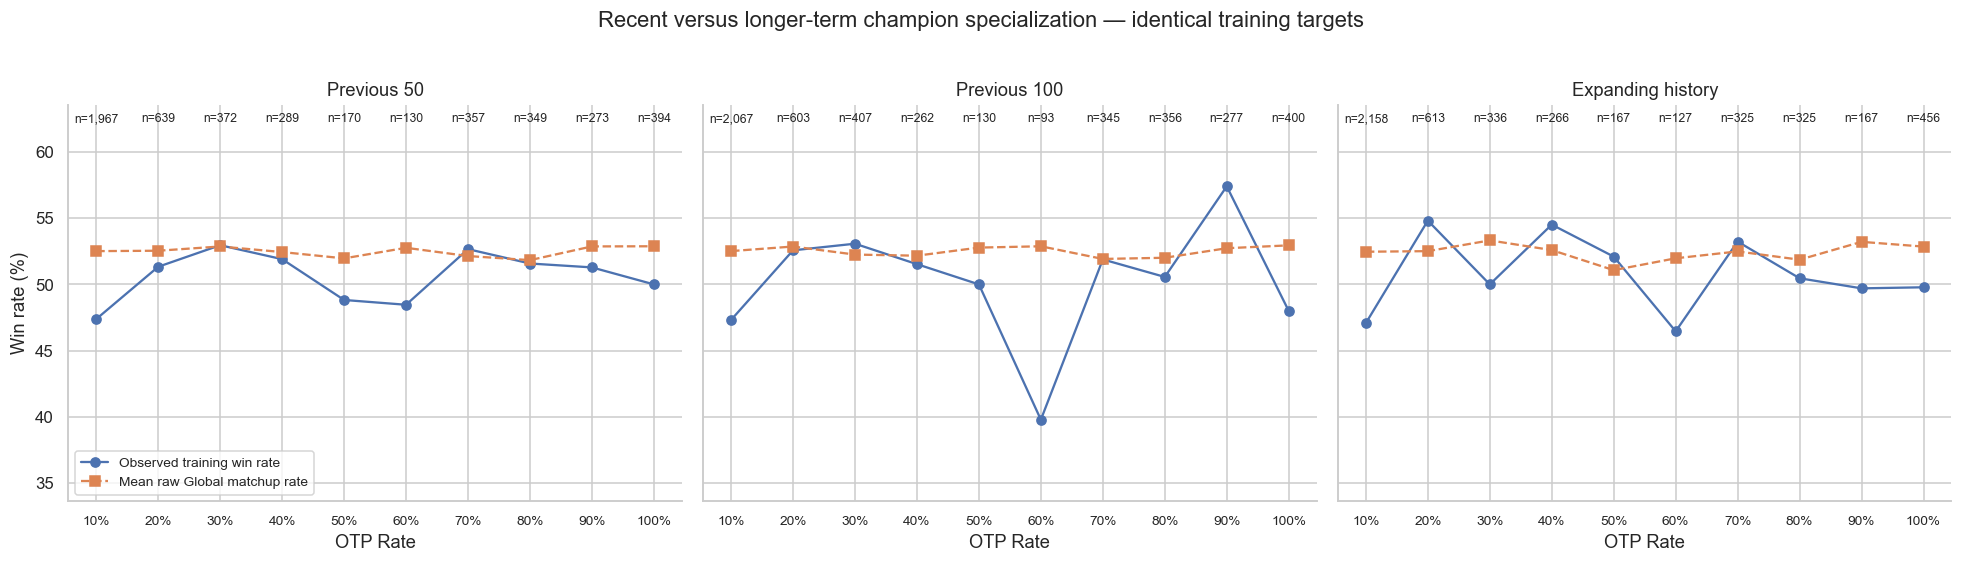

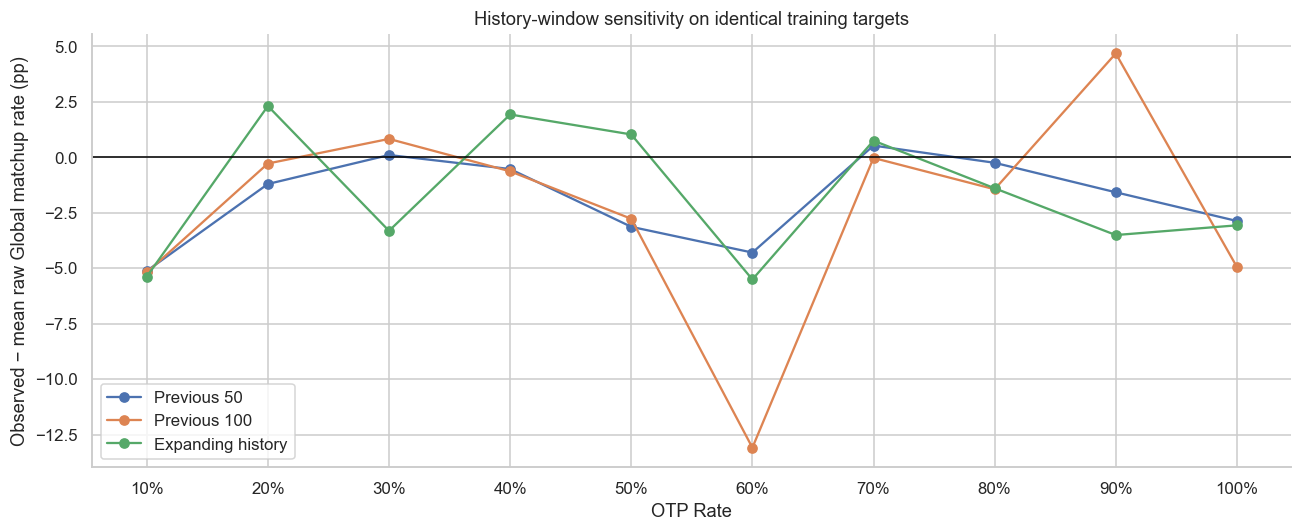

**Bin convention for both figures:** 10% denotes 0–10% selected-champion usage; 20% denotes >10–20%; successive labels are upper endpoints through 100% (>90–100%). Zero and 100% are included. Empty bins retain their positions as gaps. OTP Rate is the selected champion’s strictly pregame usage share under the stated history window, not an eligibility rule.

Usage definition,Usage bin,Observations,Unique players,Observed win rate,Mean raw Global matchup win rate,Difference (pp)
Previous 50,10%,"1,967",156,47.38%,52.51%,-5.13
Previous 50,20%,639,94,51.33%,52.54%,-1.21
Previous 50,30%,372,65,52.96%,52.86%,+0.10
Previous 50,40%,289,46,51.90%,52.44%,-0.54
Previous 50,50%,170,33,48.82%,51.96%,-3.14
Previous 50,60%,130,23,48.46%,52.76%,-4.30
Previous 50,70%,357,25,52.66%,52.14%,+0.52
Previous 50,80%,349,27,51.58%,51.83%,-0.25
Previous 50,90%,273,21,51.28%,52.87%,-1.58
Previous 50,100%,394,21,50.00%,52.88%,-2.88


Usage definition,Identical targets,Different bin from expanding,Different-bin share,Players with any reassignment,Moved at least two bins,Mean absolute usage change (pp)
Previous 50,4940,1920,38.9%,145,624,6.47
Previous 100,4940,1505,30.5%,124,244,3.81


Fixed targets: 4,940; players: 173; overall observed WR: 49.76%; overall mean Global benchmark: 52.50%.


In [21]:
rolling_usage_definitions = {
    'Previous 50':'prior50_champion_usage_share',
    'Previous 100':'prior100_champion_usage_share',
    'Expanding history':'prior_champion_usage_share'}
rolling_bin_labels = [f'{endpoint}%' for endpoint in range(10,101,10)]
rolling_bin_edges = [v/10 for v in range(11)]
rolling_summaries = {}
rolling_assignments = {}
for definition,column in rolling_usage_definitions.items():
    rolling_bins = pd.cut(rolling_common[column],bins=rolling_bin_edges,right=True,
                          include_lowest=True,labels=rolling_bin_labels)
    assert rolling_bins.notna().all()
    rolling_assignments[definition] = rolling_bins
    summary = rolling_common.groupby(rolling_bins,observed=False).agg(
        observations=('win','size'),unique_players=('puuid','nunique'),
        observed_wr=('win','mean'),expected_wr=(rolling_benchmark_col,'mean'))
    summary.index.name = 'Usage bin'
    summary['difference_pp'] = 100*(summary.observed_wr-summary.expected_wr)
    assert summary.observations.sum()==len(rolling_common)
    rolling_summaries[definition] = summary

rolling_x = np.arange(10)
fig,axes = plt.subplots(1,3,figsize=(18,5),sharex=True,sharey=True)
for ax,(definition,summary) in zip(axes,rolling_summaries.items()):
    # NaNs for unobserved bins stay NaN so line segments do not bridge empty bins.
    ax.plot(rolling_x,100*summary.observed_wr,'o-',label='Observed training win rate')
    ax.plot(rolling_x,100*summary.expected_wr,'s--',label='Mean raw Global matchup rate')
    ax.set(title=definition,xticks=rolling_x,xticklabels=rolling_bin_labels,xlabel='OTP Rate')
    ax.tick_params(axis='x',labelsize=9)
    for x,count in zip(rolling_x,summary.observations):
        ax.text(x,.98,f'n={count:,}',transform=ax.get_xaxis_transform(),ha='center',va='top',fontsize=8)
    ax.margins(y=.35)
axes[0].set_ylabel('Win rate (%)')
axes[0].legend(loc='lower left',fontsize=9)
fig.suptitle('Recent versus longer-term champion specialization — identical training targets',y=1.02)
done()
fig,ax = plt.subplots(figsize=(12,5))
for definition,summary in rolling_summaries.items():
    ax.plot(rolling_x,summary.difference_pp,'o-',label=definition)
ax.axhline(0,color='black',linewidth=1)
ax.set(xticks=rolling_x,xticklabels=rolling_bin_labels,xlabel='OTP Rate',
       ylabel='Observed − mean raw Global matchup rate (pp)',
       title='History-window sensitivity on identical training targets')
ax.legend();done()
note('**Bin convention for both figures:** 10% denotes 0–10% selected-champion usage; 20% denotes >10–20%; '
     'successive labels are upper endpoints through 100% (>90–100%). Zero and 100% are included. '
     'Empty bins retain their positions as gaps. OTP Rate is the selected champion’s strictly pregame usage share '
     'under the stated history window, not an eligibility rule.')
rolling_combined_table = pd.concat(rolling_summaries,names=['Usage definition']).reset_index().rename(columns={
    'observations':'Observations','unique_players':'Unique players','observed_wr':'Observed win rate',
    'expected_wr':'Mean raw Global matchup win rate','difference_pp':'Difference (pp)'})
display(rolling_combined_table.style.format({
    'Observations':'{:,}','Unique players':'{:,}','Observed win rate':'{:.2%}',
    'Mean raw Global matchup win rate':'{:.2%}','Difference (pp)':'{:+.2f}'},na_rep='—').hide(axis='index'))
rolling_reassignments = []
for definition in ['Previous 50','Previous 100']:
    changed = rolling_assignments[definition].ne(rolling_assignments['Expanding history'])
    code_distance = (rolling_assignments[definition].cat.codes-rolling_assignments['Expanding history'].cat.codes).abs()
    rolling_reassignments.append({'Usage definition':definition,'Identical targets':len(rolling_common),
        'Different bin from expanding':int(changed.sum()),'Different-bin share':changed.mean(),
        'Players with any reassignment':rolling_common.loc[changed,'puuid'].nunique(),
        'Moved at least two bins':int(code_distance.ge(2).sum()),
        'Mean absolute usage change (pp)':100*(rolling_common[rolling_usage_definitions[definition]]-
                                                rolling_common.prior_champion_usage_share).abs().mean()})
rolling_reassignment_table = pd.DataFrame(rolling_reassignments)
display(rolling_reassignment_table.style.format({'Different-bin share':'{:.1%}',
    'Mean absolute usage change (pp)':'{:.2f}'},na_rep='—').hide(axis='index'))
# Overall outcomes and expected rate are invariant because targets never change.
print(f'Fixed targets: {len(rolling_common):,}; players: {rolling_common.puuid.nunique()}; '
      f'overall observed WR: {rolling_common.win.mean():.2%}; '
      f'overall mean Global benchmark: {rolling_common[rolling_benchmark_col].mean():.2%}.')


In [22]:
note(f'**Retention:** the fixed comparison retains **{len(rolling_common):,}/{len(train):,} targets** from '
     f'**{rolling_common.puuid.nunique()}/{train.puuid.nunique()} training players**. '
     f'**{len(rolling_excluded):,} observations** are excluded; '
     f'**{rolling_training.prior50_champion_usage_share.isna().sum():,}** lack 50 recorded prior games and '
     f'**{rolling_training.prior100_champion_usage_share.isna().sum():,}** lack 100 (overlapping reasons). '
     f'**{rolling_lost_players} players** have no retained targets. '
     'This complete-window restriction changes the target population relative to earlier sections, '
     'but the three definitions within this section always use identical targets.')
for definition,summary in rolling_summaries.items():
    positive = summary.index[summary.difference_pp.gt(0)].tolist()
    sparse = summary.index[summary.observations.lt(30)].tolist()
    empty = summary.index[summary.observations.eq(0)].tolist()
    low,high = summary.iloc[0],summary.iloc[-1]
    note(f'**{definition}:** in the 10% bin, observed WR is **{low.observed_wr:.2%}** versus '
         f'**{low.expected_wr:.2%}** expected (**{low.difference_pp:+.2f} pp**, n={int(low.observations):,}; '
         f'{int(low.unique_players)} players). In the 100% bin, observed WR is **{high.observed_wr:.2%}** versus '
         f'**{high.expected_wr:.2%}** expected (**{high.difference_pp:+.2f} pp**, n={int(high.observations):,}; '
         f'{int(high.unique_players)} players). Positive-difference bins: **{", ".join(positive) if positive else "none"}**. '
         f'Bins with fewer than 30 rows: **{", ".join(sparse) if sparse else "none"}**; '
         f'empty bins: **{", ".join(empty) if empty else "none"}**. '
         f'Across nonempty bins, player support ranges from {summary.loc[summary.observations.gt(0),"unique_players"].min()} '
         f'to {summary.unique_players.max()} players. Thirty is only a display warning, not an inclusion threshold.')
for row in rolling_reassignment_table.itertuples(index=False,name=None):
    definition,total,changed,share,players,two_bins,mean_change = row
    note(f'**{definition} versus expanding:** **{changed:,}/{total:,} ({share:.1%})** targets move bins, '
         f'affecting **{players} players**; **{two_bins:,}** move at least two bins. '
         f'The mean absolute usage-share change is **{mean_change:.2f} pp**.')
rolling_recent100_mid = rolling_summaries['Previous 100'].loc['60%']
rolling_expanding_mid = rolling_summaries['Expanding history'].loc['60%']
note(f'**Does the pattern change?** Low-usage (10%) and highest-usage (100%) bins remain below the benchmark '
     'for all three definitions, while positive intermediate-bin differences change location. '
     'There is no consistent monotonic rise in benchmark-relative performance with usage. '
     f'A conspicuous local change is the previous-100 60% bin: '
     f'**{rolling_recent100_mid.difference_pp:+.2f} pp** from '
     f'**{int(rolling_recent100_mid.observations)} games and {int(rolling_recent100_mid.unique_players)} players**, '
     f'compared with **{rolling_expanding_mid.difference_pp:+.2f} pp** in the expanding 60% bin '
     f'(n={int(rolling_expanding_mid.observations)}; {int(rolling_expanding_mid.unique_players)} players). '
     'Those bins contain different subsets of the fixed targets; this is not a within-game performance change. '
     'The absence of cells below 30 rows does not remove uncertainty from concentrated player support.')
note('**Interpretation:** changing history windows reassigns the same observed games and benchmark values across bins, '
     'so local differences can reflect grouping changes rather than a change in overall performance. '
     'Recent windows emphasize current repertoire; expanding history incorporates more recorded past play. '
     'Complete-window support and the displayed player counts limit interpretation, even in bins with many rows. '
     'Historical coverage is bounded by the saved initial collection, and zero usage is not necessarily first-ever use. '
     'The raw Global benchmark is unchanged and retrospective; it is not an individualized forecast. '
     'Do not select a window for a desired pattern or interpret a bin boundary as an exact OTP threshold. '
     'These are descriptive sensitivity comparisons with repeated players and shared matches, not causal specialization effects. '
     'No model was fitted and no validation/test outcomes were examined.')


**Retention:** the fixed comparison retains **4,940/5,086 targets** from **173/177 training players**. **146 observations** are excluded; **4** lack 50 recorded prior games and **146** lack 100 (overlapping reasons). **4 players** have no retained targets. This complete-window restriction changes the target population relative to earlier sections, but the three definitions within this section always use identical targets.

**Previous 50:** in the 10% bin, observed WR is **47.38%** versus **52.51%** expected (**-5.13 pp**, n=1,967; 156 players). In the 100% bin, observed WR is **50.00%** versus **52.88%** expected (**-2.88 pp**, n=394; 21 players). Positive-difference bins: **30%, 70%**. Bins with fewer than 30 rows: **none**; empty bins: **none**. Across nonempty bins, player support ranges from 21 to 156 players. Thirty is only a display warning, not an inclusion threshold.

**Previous 100:** in the 10% bin, observed WR is **47.31%** versus **52.51%** expected (**-5.20 pp**, n=2,067; 157 players). In the 100% bin, observed WR is **48.00%** versus **52.95%** expected (**-4.95 pp**, n=400; 19 players). Positive-difference bins: **30%, 90%**. Bins with fewer than 30 rows: **none**; empty bins: **none**. Across nonempty bins, player support ranges from 16 to 157 players. Thirty is only a display warning, not an inclusion threshold.

**Expanding history:** in the 10% bin, observed WR is **47.08%** versus **52.46%** expected (**-5.38 pp**, n=2,158; 156 players). In the 100% bin, observed WR is **49.78%** versus **52.85%** expected (**-3.07 pp**, n=456; 19 players). Positive-difference bins: **20%, 40%, 50%, 70%**. Bins with fewer than 30 rows: **none**; empty bins: **none**. Across nonempty bins, player support ranges from 12 to 156 players. Thirty is only a display warning, not an inclusion threshold.

**Previous 50 versus expanding:** **1,920/4,940 (38.9%)** targets move bins, affecting **145 players**; **624** move at least two bins. The mean absolute usage-share change is **6.47 pp**.

**Previous 100 versus expanding:** **1,505/4,940 (30.5%)** targets move bins, affecting **124 players**; **244** move at least two bins. The mean absolute usage-share change is **3.81 pp**.

**Does the pattern change?** Low-usage (10%) and highest-usage (100%) bins remain below the benchmark for all three definitions, while positive intermediate-bin differences change location. There is no consistent monotonic rise in benchmark-relative performance with usage. A conspicuous local change is the previous-100 60% bin: **-13.09 pp** from **93 games and 18 players**, compared with **-5.51 pp** in the expanding 60% bin (n=127; 15 players). Those bins contain different subsets of the fixed targets; this is not a within-game performance change. The absence of cells below 30 rows does not remove uncertainty from concentrated player support.

**Interpretation:** changing history windows reassigns the same observed games and benchmark values across bins, so local differences can reflect grouping changes rather than a change in overall performance. Recent windows emphasize current repertoire; expanding history incorporates more recorded past play. Complete-window support and the displayed player counts limit interpretation, even in bins with many rows. Historical coverage is bounded by the saved initial collection, and zero usage is not necessarily first-ever use. The raw Global benchmark is unchanged and retrospective; it is not an individualized forecast. Do not select a window for a desired pattern or interpret a bin boundary as an exact OTP threshold. These are descriptive sensitivity comparisons with repeated players and shared matches, not causal specialization effects. No model was fitted and no validation/test outcomes were examined.